In [34]:
# Set up the environment and define functions

# Import packages
import gc
import numpy as np
import matplotlib.pyplot as plt
import os
import os.path as op
import time
import pandas as pd
import glob
import csv
import mne
from mne.preprocessing.nirs import tddr
from nilearn.glm.first_level import make_first_level_design_matrix  
from mne_nirs.channels import get_long_channels
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from scipy import signal
from scipy.stats import ttest_rel, zscore
import mne_nirs

mne.viz.set_browser_backend('matplotlib')

######### Set these variables as appropriate:
raw_path = '../../data_CI'
proc_path = '../../processed_CI'
results_path = '../../results_CI'
subjects_dir = '../../subjects_CI'
behavior_results_path = '../../fnirs-behavior-results_CI'
#behavior_file = '../../behavior_diff_data.csv'
output_suffix = "final_CI" # used for all file names that are created

sfreq = 2.403846 #4.807692
subjects =  ('104', '105', '106', '107', '108', '109', '110', '111', '112', '113')
print("N=" + str(len(subjects)))
conditions = ('A', 'V', 'AV', 'W')
groups = ('CI')
days = ('1', '3')
runs = (1, 2)
duration = 1.8
design = 'event'
filt_kwargs = dict(
    l_freq=0.01, l_trans_bandwidth=0.01,
    h_freq=0.2, h_trans_bandwidth=0.01)
n_jobs = 4  # for GLM

os.makedirs(proc_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)
os.makedirs(subjects_dir, exist_ok=True)
#mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir, verbose=True)  # Only need to run once

use = None
all_sci = list()
plt.rcParams['axes.titlesize'] = 8
plt.rcParams['axes.labelsize'] = 8
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8

# Prep making bad channels report
bad_channels_filename = op.join(results_path, f'bad_channels_report_{output_suffix}.csv')

with open(bad_channels_filename, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['Subject', 'Day', 'Run', 'Percent Bad'])

def add_bad_channel_entry(subject, day, run, percentage_bad):
    with open(bad_channels_filename, mode='a', newline='') as file:
        writer = csv.writer(file)
        writer.writerow([subject, day, run, f'{percentage_bad:.2f}%'])

def normalize_channel_names(channels_set):
    return {name.split()[0] for name in channels_set}



Using matplotlib as 2D backend.
N=10


In [35]:
# Set parameters for preprocessing

def preprocess_fnirs_data(raw_intensity, proc_path, base):
    # 1. Convert to optical density:
    print(f'    Analyzing {base}')
    raw_od = mne.preprocessing.nirs.optical_density(raw_intensity, verbose='error')

    # 2. Identify bad channels based on flat signal and scalp coupling index:
    peaks = np.ptp(raw_od.get_data('fnirs'), axis=-1)
    flat_names = [raw_od.ch_names[f].split(' ')[0] for f in np.where(peaks < 0.001)[0]]
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od)
    sci_mask = (sci < 0.25)
    got = np.where(sci_mask)[0]
    percentage_bad = (len(got) / len(raw_od.ch_names)) * 100
    assert raw_od.info['bads'] == []
    bads = set(raw_od.ch_names[pick] for pick in got)
    bads = bads | set(ch_name for ch_name in raw_od.ch_names if ch_name.split(' ')[0] in flat_names)
    bads = sorted(bads)

    # 3. Apply temporal derivative distribution repair (TDDR), bandpass filter, apply bad channels:
    raw_tddr = tddr(raw_od)
    raw_tddr_bp = raw_tddr.copy().filter(**filt_kwargs)
    raw_tddr_bp.info['bads'] = bads

    # 5. Short channel regression (if present): 
    try:
        raw_tddr_bp = mne_nirs.signal_enhancement.short_channel_regression(raw_tddr_bp)
    except:
        print(f"No short channels found for {base}.")

    # 6. Convert to hemoglobin concentration:
    raw_h = mne.preprocessing.nirs.beer_lambert_law(raw_tddr_bp, 6.)

    # 7. Normalize channel names and verify bad channels
    h_bads = [ch_name for ch_name in raw_h.ch_names if ch_name.split(' ')[0] in set(bad.split(' ')[0] for bad in bads)]
    raw_h.info['bads'] = h_bads
    raw_h.info._check_consistency()

    # 8. Select long channels and verify that the signal is not flat:
    raw_h = get_long_channels(raw_h)
    picks = mne.pick_types(raw_h.info, fnirs=True)
    peaks = np.ptp(raw_h.get_data(picks), axis=-1)
    assert (peaks > 1e-9).all()

    # Resample data??
    raw_h = raw_h.resample(sfreq=sfreq)

    # 9. Interpolate bad channels
    if raw_h.info['bads']:
        raw_h_interp = raw_h.copy().interpolate_bads(reset_bads=True, method=dict(fnirs='nearest'))
    else:
        raw_h_interp = raw_h.copy()  # No interpolation needed, just copy
    raw_h_interp.save(op.join(proc_path, f'{subject}_{day}_{run:03d}_long_hbo_{output_suffix}_raw.fif'), overwrite=True)
    assert len(raw_h.ch_names) == len(raw_h_interp.ch_names)

    return raw_h_interp, percentage_bad, bads

In [36]:
# Load participant data

for subject in subjects:
    for day in days:
        for run in runs:
            root1 = f'Day{day}'
            root2 = f'{subject}_{day}'
            root3 = f'*-*-*_{run:03d}'
            fname_base = op.join(raw_path, root1, root2, root3)
            fname = glob.glob(fname_base)
            base = f'{subject}_{day}_{run:03d}'
            base_pr = base.ljust(20)
            raw_intensity = mne.io.read_raw_nirx(fname[0])
            raw_intensity, percentage_bad_long, bads_long = preprocess_fnirs_data(raw_intensity, proc_path, base + '_long')
            add_bad_channel_entry(subject, day, run, percentage_bad_long)
            del raw_intensity, percentage_bad_long, bads_long
            gc.collect()  


Loading ../../data_CI/Day1/104_1/2023-09-15_001
    Analyzing 104_1_001_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.21 Hz)
- Filter length: 1587 samples (330.096 s)

No short channels found for 104_1_001_long.
Overwriting existing file.
Writing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/104_1_001_long_hbo_final_CI_raw.fif


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s


Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/104_1_001_long_hbo_final_CI_raw.fif
[done]
Loading ../../data_CI/Day1/104_1/2023-09-15_002
    Analyzing 104_1_002_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.21 Hz)
- Filter length: 1587 samples (330.096 s)

No short channels found for 104_1_002_long.
Setting channel interpolation method to {'fnirs': 'nearest'}.
Interpolating bad channels.


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s


    Automatic origin fit: head of radius 93.6 mm
Overwriting existing file.
Writing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/104_1_002_long_hbo_final_CI_raw.fif
Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/104_1_002_long_hbo_final_CI_raw.fif
[done]
Loading ../../data_CI/Day3/104_3/2023-09-17_001
    Analyzing 104_3_001_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.21 Hz)
- Filter length: 1587 samples (330.096 s)

No shor

...

Setting channel interpolation method to {'fnirs': 'nearest'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 93.7 mm
Writing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/113_1_002_long_hbo_final_CI_raw.fif
Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/113_1_002_long_hbo_final_CI_raw.fif
[done]
Loading ../../data_CI/Day3/113_3/2025-01-31_001
    Analyzing 113_3_001_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequen

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.1s


Setting channel interpolation method to {'fnirs': 'nearest'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 93.7 mm
Writing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/113_3_001_long_hbo_final_CI_raw.fif
Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/113_3_001_long_hbo_final_CI_raw.fif
[done]
Loading ../../data_CI/Day3/113_3/2025-01-31_002
    Analyzing 113_3_002_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequen

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s


Interpolating bad channels.
    Automatic origin fit: head of radius 93.7 mm
Writing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/113_3_002_long_hbo_final_CI_raw.fif
Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/113_3_002_long_hbo_final_CI_raw.fif
[done]


In [ ]:
""" # Remove subjects with >30% bad channels; SKIP

bad_channels_df = pd.read_csv(bad_channels_filename)
bad_channels_df['Percent Bad'] = bad_channels_df['Percent Bad'].str.rstrip('%').astype(float)
average_bad_channels = bad_channels_df.groupby('Subject')['Percent Bad'].mean()

# Find subjects with more than 30% bad channels
bad_subjects = average_bad_channels[average_bad_channels > 30].index.tolist()
print("Subjects with more than 30% bad channels:", bad_subjects)

# Initialize counters for each group
removed_CI = 0

# Count and remove the bad subjects
for subject in bad_subjects:
    removed_CI += 1

# Update the subjects list after counting the removed subjects
#subjects = [subject for subject in subjects if subject not in bad_subjects]        # UNCOMMENT TO REMOVE BAD SUBJECTS

# Output the results
print(f'Removed {removed_CI} subjects.')

# Load the bad channels data
bad_channels_df = pd.read_csv(bad_channels_filename)

# Ensure 'Percent Bad' is treated as a string, strip '%', and convert to float
bad_channels_df['Percent Bad'] = bad_channels_df['Percent Bad'].astype(str).str.rstrip('%').astype(float)

# Sort the DataFrame by 'Percent Bad' in ascending order
bad_channels_df_sorted = bad_channels_df.sort_values(by='Percent Bad')

# Plotting
plt.figure(figsize=(12, 6))
plt.bar(bad_channels_df_sorted['Subject'], bad_channels_df_sorted['Percent Bad'], color='blue', label='Percent Bad Channels')

# Highlight subjects with more than 50% bad channels
plt.bar(bad_channels_df_sorted[bad_channels_df_sorted['Percent Bad'] > 30]['Subject'],
        bad_channels_df_sorted[bad_channels_df_sorted['Percent Bad'] > 30]['Percent Bad'],
        color='red', label='> 30% Bad Channels')

plt.xlabel('Subject')
plt.ylabel('Percent Bad Channels')
plt.title('Percentage of Bad Channels per Subject')
plt.legend()
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability

# Show the plot
plt.tight_layout()
plt.show() """

In [37]:
# Clean events and make design matrix

def make_design(raw_h_long, design, subject=None, run=None, day=None, group=None):
    annotations_to_remove = raw_h_long.annotations.description == '255.0'
    raw_h_long.annotations.delete(annotations_to_remove)
    events, _ = mne.events_from_annotations(raw_h_long)
    
    # Fix mis-codings
    rows_to_remove = events[:, -1] == 1
    events = events[~rows_to_remove]
    if len(events) == 101:
        events = events[1:]

    n_times = len(raw_h_long.times)
    stim = np.zeros((n_times, 4))
    events[:, 2] -= 1
#    assert len(events) == 100, len(events)
    want = [0] + [25] * 4
    count = np.bincount(events[:, 2])
#    assert np.array_equal(count, want), count
#    assert events.shape == (100, 3), events.shape

    if design == 'block':
        events = events[0::5]
        duration = 20.
        assert np.array_equal(np.bincount(events[:, 2]), [0] + [5] * 4)
    else:
#        assert design == 'event'
#        assert len(events) == 100
        duration = 1.8
#        assert events.shape == (100, 3)
#        events_r = events[:, 2].reshape(20, 5)
#        assert (events_r == events_r[:, :1]).all()
#        del events_r
        
    idx = (events[:, [0, 2]] - [0, 1]).T
    assert np.in1d(idx[1], np.arange(len(conditions))).all()
    stim[tuple(idx)] = 1
    
    n_block = int(np.ceil(duration * sfreq))
    stim = signal.fftconvolve(stim, np.ones((n_block, 1)), axes=0)[:n_times]
    dm_events = pd.DataFrame({
        'trial_type': [conditions[ii] for ii in idx[1]],
        'onset': idx[0] / raw_h_long.info['sfreq'],
        'duration': n_block / raw_h_long.info['sfreq']})
    dm = make_first_level_design_matrix(
        raw_h_long.times, dm_events, hrf_model='glover',
        drift_model='polynomial', drift_order=0)
        
    return stim, dm, events


Opening raw data file ../../processed_CI/110_1_001_long_hbo_final_CI_raw.fif...
    Range : 0 ... 1977 =      0.000 ...   822.432 secs
Ready.
Reading 0 ... 1977  =      0.000 ...   822.432 secs...
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']


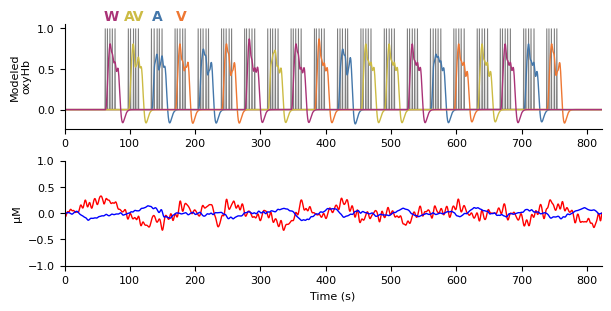

In [38]:
# Change the subject, day, and run to plot different waveforms; SKIP

plot_subject = '110'
plot_day = 1
plot_run = 1

fname2 = op.join(proc_path, f'{plot_subject}_{plot_day}_{plot_run:03d}_long_hbo_{output_suffix}_raw.fif')
use = mne.io.read_raw_fif(fname2, preload=True)
events, _ = mne.events_from_annotations(use)
ch_names = [ch_name.rstrip(' hbo') for ch_name in use.ch_names]
info = use.info

fig, axes = plt.subplots(2, 1, figsize=(6., 3), constrained_layout=True)
ax = axes[0]
raw_h = use
stim, dm, _ = make_design(raw_h, design)

colors = dict(
    A='#4477AA',  # blue
    AV='#CCBB44',  # yellow
    V='#EE7733',  # orange
    W='#AA3377',  # purple
)

for ci, condition in enumerate(conditions):
    color = colors[condition]
    ax.fill_between(
        raw_h.times, stim[:, ci], 0, edgecolor='none', facecolor='k',
        alpha=0.5)
    model = dm[conditions[ci]].to_numpy()
    ax.plot(raw_h.times, model, ls='-', lw=1, color=color)
    x = raw_h.times[np.where(model > 0)[0][0]]
    ax.text(
        x + 10, 1.1, condition, color=color, fontweight='bold', ha='center')
ax.set(ylabel='Modeled\noxyHb', xlabel='', xlim=raw_h.times[[0, -1]])

# HbO/HbR
ax = axes[1]
picks = [pi for pi, ch_name in enumerate(raw_h.ch_names)
         if 'S7_D19' in ch_name]
colors = dict(hbo='r', hbr='b')
ylim = np.array([-1, 1])
for pi, pick in enumerate(picks):
    color = colors[raw_h.ch_names[pick][-3:]]
    data = raw_h.get_data(pick)[0] * 1e6
    val = np.ptp(data)
    assert val > 0.01
    ax.plot(raw_h.times, data, color=color, lw=1.)
ax.set(ylim=ylim, xlabel='Time (s)', ylabel='μM',
       xlim=raw_h.times[[0, -1]])
for ax in axes:
    for key in ('top', 'right'):
        ax.spines[key].set_visible(False)
plt.savefig(op.join(results_path, f'figure_1_{output_suffix}.png'))


In [39]:
# Run GLM analysis and epoching

subj_cha_list = []
for subject in subjects:
    for day in days:
        for run in runs:
            fname_long = op.join(proc_path, f'{subject}_{day}_{run:03d}_long_hbo_final_CI_raw.fif')
            raw_h_long = mne.io.read_raw_fif(fname_long)
            _, dm, _ = make_design(raw_h_long, design, subject, run, day)
            glm_est = mne_nirs.statistics.run_glm(
                raw_h_long, dm, noise_model='ols', n_jobs=n_jobs)
            cha = glm_est.to_dataframe()
            cha['subject'] = subject
            cha['run'] = run
            cha['day'] = day
            cha['group'] = "CI"
            subj_cha_list.append(cha)
            del raw_h_long, dm, glm_est, cha
            gc.collect()  #
        print(f'***Finished processing subject {subject} day {day}.')

df_cha = pd.concat(subj_cha_list, ignore_index=True)
df_cha.reset_index(drop=True, inplace=True)


Opening raw data file ../../processed_CI/104_1_001_long_hbo_final_CI_raw.fif...
    Range : 0 ... 2061 =      0.000 ...   857.376 secs
Ready.
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']
Opening raw data file ../../processed_CI/104_1_002_long_hbo_final_CI_raw.fif...
    Range : 0 ... 1992 =      0.000 ...   828.672 secs
Ready.
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']
***Finished processing subject 104 day 1.
Opening raw data file ../../processed_CI/104_3_001_long_hbo_final_CI_raw.fif...
    Range : 0 ... 1985 =      0.000 ...   825.760 secs
Ready.
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']
Opening raw data file ../../processed_CI/104_3_002_long_hbo_final_CI_raw.fif...
    Range : 0 ... 1978 =      0.000 ...   822.848 secs
Ready.
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']
***Finished processing subject 104 day 3.
Opening raw data file ../../processed_CI/105_1_001_long_hbo_final_CI_raw.fif...


In [40]:
# Block averages

event_id = {condition: ci for ci, condition in enumerate(conditions, 1)}
evokeds = {condition: dict() for condition in conditions}
for day in days:
    for subject in subjects:
        fname = op.join(proc_path, f'{subject}_{day}_{output_suffix}-ave.fif')
        tmin, tmax = -2, 38
        baseline = (None, 0)
        t0 = time.time()
        print(f'Creating block average for {subject} day {day}... ', end='')
        raws = list()
        events = list()
        for run in runs:
            fname2 = op.join(proc_path, f'{subject}_{day}_{run:03d}_long_hbo_{output_suffix}_raw.fif')
            raw_h = mne.io.read_raw_fif(fname2)
            events.append(make_design(raw_h, None, 'block', subject, run)[2])
            raws.append(raw_h)
        bads = sorted(set(sum((r.info['bads'] for r in raws), [])))
        for r in raws:
            r.info['bads'] = bads
        raw_h, events = mne.concatenate_raws(raws, events_list=events)
        epochs = mne.Epochs(raw_h, events, event_id, tmin=tmin, tmax=tmax,
                            baseline=baseline)
        this_ev = [epochs[condition].average() for condition in conditions]
        assert all(ev.nave > 0 for ev in this_ev)
        mne.write_evokeds(fname, this_ev, overwrite=True)
        print(f'{time.time() - t0:0.1f} sec')
        for condition in conditions:
            evokeds[condition][subject] = mne.read_evokeds(fname, condition)
        print(f'Done for {subject} day {day} run {run:03d}... ', end='')
        del raws, events, raw_h, epochs, this_ev
        gc.collect()  #

# Mark bad channels
bad = dict()
bb = dict()

for day in days:
    for subject in subjects:
        for run in runs:
            fname2 = op.join(proc_path, f'{subject}_{day}_{run:03d}_long_hbo_{output_suffix}_raw.fif')
            this_info = mne.io.read_info(fname2)
            bad_channels = [idx - 1 for idx in sorted(
                this_info['ch_names'].index(bad) + 1 for bad in this_info['bads'])]
            valid_indices = np.arange(len(use.ch_names))
            bb = [b for b in bad_channels if b in valid_indices]
            bad[(subject, run, day)] = bb
        assert np.in1d(bad[(subject, run, day)], np.arange(len(use.ch_names))).all()

bad_combo = dict()
for day in days:
    for (subject, run, day), bb in bad.items():
        bad_combo[subject] = sorted(set(bad_combo.get(subject, [])) | set(bb))
bad = bad_combo

start = len(df_cha)
n_drop = 0
for day in days:
    for (subject, run, day), bb in bad.items():
        if not len(bb):
            continue
        drop_names = [use.ch_names[b] for b in bb]
        is_subject = (df_cha['subject'] == subject)
        is_day = (df_cha['day'] == day)
        drop = df_cha.index[
            is_subject &
            is_day &
            np.in1d(df_cha['ch_name'], drop_names)]
        n_drop += len(drop)
        if len(drop):
            print(f'Dropping {len(drop)} for {subject} day {day}')
            df_cha.drop(drop, inplace=True)
end = len(df_cha)
assert n_drop == start - end, (n_drop, start - end)

# Combine runs by averaging
sorts = ['subject', 'ch_name', 'Chroma', 'Condition', 'day', 'run']
df_cha.sort_values(sorts, inplace=True)
theta = np.array(df_cha['theta']).reshape(-1, len(runs)).mean(-1)
df_cha.drop(
    [col for col in df_cha.columns if col not in sorts[:-1]], axis='columns',
    inplace=True)
df_cha.reset_index(drop=True, inplace=True)
df_cha = df_cha[::len(runs)]
df_cha.reset_index(drop=True, inplace=True)
df_cha['theta'] = theta

Creating block average for 104 day 1... Opening raw data file ../../processed_CI/104_1_001_long_hbo_final_CI_raw.fif...
    Range : 0 ... 2061 =      0.000 ...   857.376 secs
Ready.
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']
Opening raw data file ../../processed_CI/104_1_002_long_hbo_final_CI_raw.fif...
    Range : 0 ... 1992 =      0.000 ...   828.672 secs
Ready.
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']
Not setting metadata
200 matching events found
Setting baseline interval to [-2.0800001110839905, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Overwriting existing file.
0.9 sec
Reading /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_CI/104_1_final_CI-ave.fif ...
    Found the data of interest:
        t =   -2080.00 ...   37856.00 ms (A)
        0 CTF compensation matrices available
        nave = 50 - aspect type = 100
No projector specified for this dataset. Plea

In [41]:
# Calculate HbDiff

# Load the data
df_cha_nolabels = df_cha.copy()
df_cha_nolabels['ch_name'] = df_cha_nolabels['ch_name'].str[:-4]

# Separate HbO and HbR
df_hbo = df_cha_nolabels[df_cha_nolabels['Chroma'].str.endswith('hbo')].set_index(['subject', 'Condition', 'day', 'ch_name']).sort_index()
df_hbr = df_cha_nolabels[df_cha_nolabels['Chroma'].str.endswith('hbr')].set_index(['subject', 'Condition', 'day', 'ch_name']).sort_index()

# Compute the difference
df_cha_diff_list = []
for ch_name in df_hbo.index.get_level_values('ch_name').unique():
    # Get aligned indices
    df_hbo_ch = df_hbo.loc[(slice(None), slice(None), slice(None), ch_name), :].sort_index()
    df_hbr_ch = df_hbr.loc[(slice(None), slice(None), slice(None), ch_name), :].sort_index()
    
    # Ensure df_hbo_ch and df_hbr_ch have the same length
    common_index = df_hbo_ch.index.intersection(df_hbr_ch.index)
    df_hbo_ch = df_hbo_ch.loc[common_index]
    df_hbr_ch = df_hbr_ch.loc[common_index]
    
    # Calculate the difference
    df_diff = df_hbo_ch[['theta']].sub(df_hbr_ch[['theta']])
    
    # Align df_cha_ch with df_diff
    df_cha_ch = df_hbo_ch.reset_index()
    df_cha_ch['theta'] = df_diff.values
    df_cha_ch['Chroma'] = 'hbdiff'
    df_cha_ch['ch_name'] = df_cha_ch['ch_name'] + ' hbdiff'
    
    if not df_cha_ch.empty:
        df_cha_diff_list.append(df_cha_ch)

df_cha_diff_concat = pd.concat(df_cha_diff_list, ignore_index=True)

# Concatenate original df_cha with df_cha_diff_concat
df_final = pd.concat([df_cha, df_cha_diff_concat], ignore_index=True)
df_final.to_csv(op.join(results_path, f'df_combined_final_n10.csv'), index=False)


Run correlational analyses below.

In [1]:
import os.path as op
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import ValueWarning
import warnings
warnings.filterwarnings("ignore", category=ValueWarning) 
warnings.filterwarnings("ignore", category=UserWarning) 
from scipy.stats import ttest_rel, zscore
import mne 
import numpy as np
import gc

behavior_file = '../../behavior_diff_data_CI.csv'
behavior_df = pd.read_csv(behavior_file)
behavior_df['subject'] = behavior_df['subject'].astype(str)

output_suffix = 'n10'
df_final = pd.read_csv(op.join(f'../../results_CI/df_combined_final_n10.csv'))
theta_df = df_final.copy()
theta_df['subject'] = theta_df['subject'].astype(str)
results_path = '../../results_CI/correlations'

conditions = ['A', 'AV', 'V']
response_vars = ['AO_WR', 'AV_WR', 'TBW']
chromas = ['hbdiff']
days = [1, 3]
subjects =  ('104', '105', '106', '107', '108', '109', '110', '111', '112', '113')

In [14]:
# Change in theta vs change in WR -- ROI

import os
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib as mpl
from statsmodels.stats.multitest import multipletests
from scipy.stats import zscore
import numpy as np
import re  # For cleaning ROI names

# Load the files
df_final = pd.read_csv('../../results_CI/df_combined_final_n10.csv')
behavior_df = pd.read_csv('../../results_CI/behavior_diff_data_CI.csv')

# Filter for hbdiff chroma
theta_df = df_final[df_final['Chroma'] == 'hbdiff'].copy()

# Convert subject to string for consistency
theta_df['subject'] = theta_df['subject'].astype(str)
behavior_df['subject'] = behavior_df['subject'].astype(str)

# **Debugging Step 1A: Check Subject Counts Before Processing**
print("\n=== Debugging Step 1A: Subject Counts Before Processing ===")
print(f"Unique Subjects in theta_df (hbdiff only): {theta_df['subject'].nunique()}")
print(f"Unique Subjects in behavior_df: {behavior_df['subject'].nunique()}")

# Load specificity data
hemi_specificity_path = os.path.join("../../results_CI/specificity_with_optodes.csv")
hemi_specificity = pd.read_csv(hemi_specificity_path)

# Ensure ch_name consistency: Remove chroma suffixes
theta_df['ch_name_clean'] = theta_df['ch_name'].str.split().str[0].str.strip().str.lower()
hemi_specificity['ch_name_clean'] = hemi_specificity['ch_name'].str.split().str[0].str.strip().str.lower()

# Merge using cleaned ch_name
theta_df = theta_df.merge(
    hemi_specificity[['ch_name_clean', 'Hemisphere', 'Landmark']], 
    on='ch_name_clean', 
    how='left'
)

# Drop rows where Hemisphere/Landmark is NaN
theta_df = theta_df.dropna(subset=['Hemisphere', 'Landmark'])

# Create ROI variable
theta_df['ROI'] = theta_df['Hemisphere'].astype(str) + '_' + theta_df['Landmark'].astype(str)
theta_df['ROI'] = theta_df['ROI'].str.replace(r'[^a-zA-Z0-9_]', '_', regex=True)  # Remove special characters
theta_df['ROI'] = theta_df['ROI'].str.replace('__+', '_', regex=True)  # Replace multiple underscores with one
theta_df['ROI'] = theta_df['ROI'].str.strip('_')  # Remove leading/trailing underscores

# **Debugging Step 2: Verify Merge and ROI Creation**
print("\n=== Debugging Step 2: Merged Theta DataFrame Preview ===")
print(theta_df[['ch_name', 'ROI']].drop_duplicates().head())

# Remove outside brain ROIs
theta_df = theta_df[~theta_df['ROI'].isin(["Right_Brain_Outside", "Left_Brain_Outside"])]
num_rois = theta_df['ROI'].nunique()
print(f"\n=== Number of Unique ROIs: {num_rois} ===")

# Perform analysis
def perform_analysis(theta_df, behavior_df, conditions, response_vars, results_path):
    significant_models = []
    uncorrected_significant_models = []  # Store models with p < 0.05 before FDR

    # Compute z-score per channel within each condition and ROI
    theta_df['z_theta'] = theta_df.groupby(['Condition', 'Chroma', 'ch_name'])['theta'].transform(zscore)

    # Split data into Day 1 and Day 3
    day_1 = theta_df[theta_df['day'] == 1].copy()
    day_3 = theta_df[theta_df['day'] == 3].copy()

    # **Debugging Step 3: Check Subject Counts Before Merging Days**
    print(f"\n=== Debugging Step 3: Data Counts Before Merging ===")
    print(f"Day 1 Unique Subjects: {day_1['subject'].nunique()}, Day 3 Unique Subjects: {day_3['subject'].nunique()}")

    # Merge Day 1 and Day 3 at the channel level
    theta_diff_df = pd.merge(
        day_1[['subject', 'Condition', 'ROI', 'z_theta']],
        day_3[['subject', 'Condition', 'ROI', 'z_theta']],
        on=['subject', 'Condition', 'ROI'],
        how='inner',
        suffixes=('_day1', '_day3')
    )

    # Compute z_diff at the channel level
    theta_diff_df['z_diff'] = theta_diff_df['z_theta_day3'] - theta_diff_df['z_theta_day1']

    # Aggregate by ROI: Compute mean z_diff for each ROI per subject
    roi_diff_df = theta_diff_df.groupby(['subject', 'Condition', 'ROI'])['z_diff'].mean().reset_index()

    # **Debugging Step 4: Check Aggregated ROI Data**
    print("\n=== Debugging Step 4: Aggregated ROI Data Preview ===")
    print(roi_diff_df.head())

    # **Check Subject Loss Before Merging with Behavior Data**
    print(f"\n=== Debugging Step 5: Subject Counts Before Behavior Merge ===")
    print(f"Unique Subjects in ROI Diff Data: {roi_diff_df['subject'].nunique()}")

    # Merge with behavior data
    merged_df = pd.merge(
        roi_diff_df,
        behavior_df[['subject'] + response_vars],  
        on='subject'
    )

    # **Debugging Step 6: Check Merged Data**
    print("\n=== Debugging Step 6: Merged Data Preview ===")
    print(merged_df.head())

    for condition in conditions:
        for response_var in response_vars:
            df = merged_df[merged_df['Condition'] == condition][['ROI', response_var, 'z_diff']].dropna()

            # **Check if DF is Empty**
            if df.empty:
                print(f"\n⚠️ WARNING: No data for condition {condition} - {response_var}")
                continue

            p_values = []
            model_data = []

            for roi in df['ROI'].unique():
                df_roi = df[df['ROI'] == roi]

                if df_roi.shape[0] < 5 or df_roi['z_diff'].std() == 0:
                    print(f"Skipping {roi} ({condition}, {response_var}) due to insufficient data")
                    continue

                try:
                    model = smf.ols(f"{response_var} ~ z_diff", df_roi).fit()
                    p_value = model.pvalues['z_diff']
                    r_sq = model.rsquared

                    p_values.append(p_value)
                    model_data.append((roi, model, r_sq, df_roi))

                    # Save models with **uncorrected** p < 0.05
                    if p_value < 0.05:
                        uncorrected_significant_models.append({
                            'condition': condition,
                            'response_var': response_var,
                            'ROI': roi,
                            'r_squared': r_sq,
                            'p_value': p_value
                        })

                        # Plot the data
                        plt.figure(figsize=(8, 6))
                        plt.scatter(df_roi['z_diff'], df_roi[response_var], 
                                                color=response_colors.get(response_var, "black"), 
                                                s=80, alpha=0.7)
                        plt.plot(df_roi['z_diff'], model.fittedvalues, color='black', linewidth=2)

                        plt.xticks(fontsize=16)  # Increase x-axis numbers
                        plt.yticks(fontsize=16)  # Increase y-axis numbers
                        plt.xlabel(f'{roi} z_diff', fontsize=18, color='black')
                        plt.ylabel(f'Δ {response_var}', fontsize=18, color='black')
                        plt.title(f'Change in {roi} Activity vs. \nChange in {response_var} ({condition})', fontsize=18)
                        plt.tight_layout()

                        # Save plot
                        plot_filename = os.path.join(results_path,  f"{prefix}_correlation_{roi}_{response_var}_{condition}.png")
                        plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
                        plt.close()


                except Exception as e:
                    print(f"Error fitting model for {roi}: {e}")
                    continue

            if not p_values:
                print(f"\n⚠️ WARNING: No valid models for condition {condition} - {response_var}")
                continue

            # **Perform FDR Correction**
            rejected, p_values_corrected, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')

            for i, (roi, model, r_sq, df_roi) in enumerate(model_data):
                if p_values[i] < 0.05:
                    print(f"✅ Significant {roi} | {response_var} | {condition}: p={p_values[i]}, corrected p={p_values_corrected[i]}, R^2={r_sq}")

                    significant_models.append({
                        'condition': condition,
                        'response_var': response_var,
                        'ROI': roi,
                        'r_squared': r_sq,
                        'p_value': p_values[i],
                        'p_value_corrected': p_values_corrected[i]
                    })

    # **Save results to CSV**
    pd.DataFrame(significant_models).to_csv(os.path.join(results_path,  f"{prefix}_correlations.csv"), index=False)

    print("\n✅ Analysis complete. Results saved.")

# Run analysis - words
response_colors = {
    "AO_WR": "#E69F00",  # Orange
    "AV_WR": "#009E73",  # Teal/Green
    "VO_WR": "#0072B2"   # Blue
}
prefix = 'words'
perform_analysis(theta_df, behavior_df, conditions=['A', 'AV', 'V'], response_vars=['AO_WR', 'AV_WR', 'VO_WR', 'TBW'], results_path="../../results_CI")


# Run analysis - phonemes
response_colors = {
    "AO_PH": "#E69F00",  # Orange
    "AV_PH": "#009E73",  # Teal/Green
    "VO_PH": "#0072B2"   # Blue
}

prefix = 'phonemes'
perform_analysis(theta_df, behavior_df, conditions=['A', 'AV', 'V'], response_vars=['AO_PH', 'AV_PH', 'VO_PH'], results_path="../../results_CI")



=== Debugging Step 1A: Subject Counts Before Processing ===
Unique Subjects in theta_df (hbdiff only): 10
Unique Subjects in behavior_df: 13

=== Debugging Step 2: Merged Theta DataFrame Preview ===
          ch_name                               ROI
0  S10_D18 hbdiff    Right_21_Middle_Temporal_gyrus
1  S10_D18 hbdiff  Right_22_Superior_Temporal_Gyrus
2  S10_D18 hbdiff      Right_48_Retrosubicular_area
3  S10_D18 hbdiff        Right_38_Temporopolar_area
4  S10_D18 hbdiff  Right_20_Inferior_Temporal_gyrus

=== Number of Unique ROIs: 52 ===

=== Debugging Step 3: Data Counts Before Merging ===
Day 1 Unique Subjects: 10, Day 3 Unique Subjects: 10

=== Debugging Step 4: Aggregated ROI Data Preview ===
  subject Condition                                   ROI    z_diff
0     104         A      Left_17_Primary_Visual_Cortex_V1 -0.537358
1     104         A  Left_18_Visual_Association_Cortex_V2 -0.253600
2     104         A                            Left_19_V3 -0.086634
3     104         A

In [ ]:
# Baseline theta predictors of WR changes -- ROI

import os
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib as mpl
from statsmodels.stats.multitest import multipletests
from scipy.stats import zscore
import numpy as np
import re  # For cleaning ROI names
import mne
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Load the files
df_final = pd.read_csv('../../results_CI/df_combined_final_n10.csv')
behavior_df = pd.read_csv('../../results_CI/behavior_diff_data_CI.csv')
subjects_dir = '../../subjects_CI'

# Load raw file to extract channel locations
raw_file_path = f"../../processed_CI/113_3_002_long_hbo_final_CI_raw.fif"
raw = mne.io.read_raw_fif(raw_file_path, preload=True)
raw.load_data()

# Ensure unique renaming of channels
existing_ch_names = raw.info['ch_names']
new_ch_names = {}
seen_names = {}
for ch in existing_ch_names:
    base_name = ch.split(' ')[0]  # Remove spaces or suffixes
    if base_name in seen_names:
        seen_names[base_name] += 1
        new_name = f"{base_name}_{seen_names[base_name]}"  # Append index to duplicate names
    else:
        seen_names[base_name] = 1
        new_name = base_name

    new_ch_names[ch] = new_name
raw.rename_channels(new_ch_names)

# Filter for hbdiff chroma
theta_df = df_final[df_final['Chroma'] == 'hbdiff'].copy()

# Convert subject to string for consistency
theta_df['subject'] = theta_df['subject'].astype(str)
behavior_df['subject'] = behavior_df['subject'].astype(str)

# **Debugging Step 1A: Check Subject Counts Before Processing**
print("\n=== Debugging Step 1A: Subject Counts Before Processing ===")
print(f"Unique Subjects in theta_df (hbdiff only): {theta_df['subject'].nunique()}")
print(f"Unique Subjects in behavior_df: {behavior_df['subject'].nunique()}")

# Load specificity data
hemi_specificity_path = os.path.join("../../results_CI/specificity_with_optodes.csv")
hemi_specificity = pd.read_csv(hemi_specificity_path)

# Ensure ch_name consistency: Remove chroma suffixes
theta_df['ch_name_clean'] = theta_df['ch_name'].str.split().str[0].str.strip().str.lower()
hemi_specificity['ch_name_clean'] = hemi_specificity['ch_name'].str.split().str[0].str.strip().str.lower()

# Merge using cleaned ch_name
theta_df = theta_df.merge(
    hemi_specificity[['ch_name_clean', 'Hemisphere', 'Landmark']], 
    on='ch_name_clean', 
    how='left'
)

# Drop rows where Hemisphere/Landmark is NaN
theta_df = theta_df.dropna(subset=['Hemisphere', 'Landmark'])

# Create ROI variable
theta_df['ROI'] = theta_df['Hemisphere'].astype(str) + '_' + theta_df['Landmark'].astype(str)
theta_df['ROI'] = theta_df['ROI'].str.replace(r'[^a-zA-Z0-9_]', '_', regex=True)  # Remove special characters
theta_df['ROI'] = theta_df['ROI'].str.replace('__+', '_', regex=True)  # Replace multiple underscores with one
theta_df['ROI'] = theta_df['ROI'].str.strip('_')  # Remove leading/trailing underscores

# **Debugging Step 2: Verify Merge and ROI Creation**
print("\n=== Debugging Step 2: Merged Theta DataFrame Preview ===")
print(theta_df[['ch_name', 'ROI']].drop_duplicates().head())

# Remove outside brain ROIs
theta_df = theta_df[~theta_df['ROI'].isin(["Right_Brain_Outside", "Left_Brain_Outside"])]
num_rois = theta_df['ROI'].nunique()
print(f"\n=== Number of Unique ROIs: {num_rois} ===")

# Perform analysis
def perform_analysis(theta_df, behavior_df, conditions, response_vars, results_path):
    significant_models = []
    uncorrected_significant_models = []  # Store models with p < 0.05 before FDR

    # Compute z-score per channel within each condition and ROI
    theta_df['z_theta'] = theta_df.groupby(['Condition', 'Chroma', 'ch_name'])['theta'].transform(zscore)

    # Split data into Day 1 and Day 3
    day_1 = theta_df[theta_df['day'] == 1].copy()

    # **Debugging Step 3: Check Subject Counts Before Merging Days**
    print(f"\n=== Debugging Step 3: Data Counts Before Merging ===")
    print(f"Day 1 Unique Subjects: {day_1['subject'].nunique()}")

    # Merge Day 1 and Day 3 at the channel level
    theta_diff_df = day_1[['subject', 'Condition', 'ROI', 'z_theta']].copy()

    # Rename z_theta to avoid confusion
    theta_diff_df = theta_diff_df.rename(columns={'z_theta': 'z_theta_day1'})

    # Aggregate by ROI: Compute mean z_diff for each ROI per subject
    roi_diff_df = theta_diff_df.groupby(['subject', 'Condition', 'ROI'])['z_theta_day1'].mean().reset_index()

    # **Debugging Step 4: Check Aggregated ROI Data**
    print("\n=== Debugging Step 4: Aggregated ROI Data Preview ===")
    print(roi_diff_df.head())

    # **Check Subject Loss Before Merging with Behavior Data**
    print(f"\n=== Debugging Step 5: Subject Counts Before Behavior Merge ===")
    print(f"Unique Subjects in ROI Diff Data: {roi_diff_df['subject'].nunique()}")

    # Merge with behavior data
    merged_df = pd.merge(
        roi_diff_df,
        behavior_df[['subject'] + response_vars],  
        on='subject'
    )

    # **Debugging Step 6: Check Merged Data**
    print("\n=== Debugging Step 6: Merged Data Preview ===")
    print(merged_df.head())

    for condition in conditions:
        for response_var in response_vars:
            df = merged_df[merged_df['Condition'] == condition][['ROI', response_var, 'z_theta_day1']].dropna()

            # **Check if DF is Empty**
            if df.empty:
                print(f"\n⚠️ WARNING: No data for condition {condition} - {response_var}")
                continue

            p_values = []
            model_data = []

            for roi in df['ROI'].unique():
                df_roi = df[df['ROI'] == roi]

                if df_roi.shape[0] < 5 or df_roi['z_theta_day1'].std() == 0:
                    print(f"Skipping {roi} ({condition}, {response_var}) due to insufficient data")
                    continue

                try:
                    model = smf.ols(f"{response_var} ~ z_theta_day1", df_roi).fit()
                    p_value = model.pvalues['z_theta_day1']
                    r_sq = model.rsquared

                    p_values.append(p_value)
                    model_data.append((roi, model, r_sq, df_roi))

                    # Save models with **uncorrected** p < 0.05
                    if p_value < 0.05:
                        uncorrected_significant_models.append({
                            'condition': condition,
                            'response_var': response_var,
                            'ROI': roi,
                            'r_squared': r_sq,
                            'p_value': p_value
                        })

                        # Collect all significant ROIs and their z_scores per condition-response_var
                        sig_rois = []
                        roi_z_scores = {}
                        
                        # Collect all significant ROIs across conditions and response_vars
                        significant_roi_scores = {}

                        for condition in conditions:
                            for response_var in response_vars:
                                sig_models = [entry for entry in uncorrected_significant_models if entry["condition"] == condition and entry["response_var"] == response_var]

                                if not sig_models:
                                    print(f"\n⚠️ No significant ROIs for {condition} - {response_var}, skipping brain plot.")
                                    continue

                                # Get ROIs with uncorrected p < 0.05
                                sig_rois = [entry["ROI"] for entry in sig_models]

                                # Extract the corresponding z_theta_day1 values for those ROIs
                                roi_z_scores = theta_diff_df[theta_diff_df["ROI"].isin(sig_rois)].groupby("ROI")["z_theta_day1"].mean()

                                # Prepare data for brain visualization
                                highlight_values = np.zeros(len(raw.ch_names))  # Default to zeros

                                # Map ROI z-scores onto MNE channels
                                for roi, score in roi_z_scores.items():
                                    for idx, ch_name in enumerate(raw.ch_names):
                                        if roi in ch_name:
                                            highlight_values[idx] = score  # Assign correct score

                                print(f"Nonzero highlight values count: {np.count_nonzero(highlight_values)}")

                                # Skip plotting if all values remain zero (no significant ROIs mapped)
                                if np.all(highlight_values == 0):
                                    print(f"\n⚠️ No valid significant ROIs for {condition} - {response_var}. Skipping brain plot.")
                                    continue

                                # Create EvokedArray for visualization
                                evoked = mne.EvokedArray(highlight_values[:, np.newaxis], raw.info)

                                # Generate STC (source time course)
                                stc = mne.stc_near_sensors(
                                    evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
                                    distance=0.02, project=True, picks=np.arange(len(raw.ch_names)), subjects_dir=subjects_dir
                                )

                                # Define the color mapping
                                cmap = LinearSegmentedColormap.from_list("blue_white_red", ["blue", "white", "red"], N=256)

                                # Plot the brain with all significant ROIs in one visualization
                                brain = stc.plot(
                                    hemi='both', views=['lat', 'frontal', 'lat'],
                                    cortex='low_contrast', time_viewer=False, show_traces=False,
                                    surface='pial', smoothing_steps=0, size=(1200, 400),
                                    clim=dict(kind='value', lims=[-1, 0, 1]),
                                    colormap='RdBu_r', view_layout='horizontal',
                                    colorbar=(-1, 1), time_label='', background='w',
                                    brain_kwargs=dict(units='m'),
                                    add_data_kwargs=dict(colorbar_kwargs=dict(
                                        title_font_size=12, label_font_size=8, n_labels=3,
                                        title=f'Z Theta Day 1 Values ({condition} - {response_var})'
                                    )),
                                    subjects_dir=subjects_dir
                                )

                                brain.show_view('lat', hemi='lh', row=0, col=0)
                                brain.show_view(azimuth=270, elevation=90, row=0, col=1)
                                brain.show_view('lat', hemi='rh', row=0, col=2)

                                # Capture and save the plot
                                screenshot = brain.screenshot(time_viewer=False)
                                brain.close()

                                fig, ax = plt.subplots(figsize=(10, 5))
                                ax.imshow(screenshot)
                                ax.axis('off')

                                plt.tight_layout()
                                plt.savefig(f"{results_path}/brain_plot_baseline_theta_{condition}_{response_var}.png")
                                plt.show()
                                plt.close(fig)

                except Exception as e:
                    print(f"Error fitting model for {roi}: {e}")
                    continue

            if not p_values:
                print(f"\n⚠️ WARNING: No valid models for condition {condition} - {response_var}")
                continue

            # **Perform FDR Correction**
            rejected, p_values_corrected, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')

            for i, (roi, model, r_sq, df_roi) in enumerate(model_data):
                if p_values[i] < 0.05:
                    print(f"✅ Significant {roi} | {response_var} | {condition}: p={p_values[i]}, corrected p={p_values_corrected[i]}, R^2={r_sq}")

                    significant_models.append({
                        'condition': condition,
                        'response_var': response_var,
                        'ROI': roi,
                        'r_squared': r_sq,
                        'p_value': p_values[i],
                        'p_value_corrected': p_values_corrected[i]
                    })

    # **Save results to CSV**
    pd.DataFrame(significant_models).to_csv(os.path.join(results_path, f"{prefix}_theta_WR_changes.csv"), index=False)
    print("\n✅ Analysis complete. Results saved.")


# Run analysis - phonemes
response_colors = {
    "AO_PH": "#E69F00",  # Orange
    "AV_PH": "#009E73",  # Teal/Green
    "VO_PH": "#0072B2"   # Blue
}
prefix = 'phonemes_change_baseline_theta'
perform_analysis(theta_df, behavior_df, conditions=['A', 'AV', 'V'], response_vars=['AO_PH', 'AV_PH', 'VO_PH'], results_path="../../results_CI")

# Run analysis - words
response_colors = {
    "AO_WR": "#E69F00",  # Orange
    "AV_WR": "#009E73",  # Teal/Green
    "VO_WR": "#0072B2"   # Blue
}
prefix = 'words_change_baseline_theta'
perform_analysis(theta_df, behavior_df, conditions=['A', 'AV', 'V'], response_vars=['AO_WR', 'AV_WR', 'VO_WR', 'TBW'], results_path="../../results_CI")



Opening raw data file ../../processed_CI/113_3_002_long_hbo_final_CI_raw.fif...
    Range : 0 ... 1974 =      0.000 ...   821.184 secs
Ready.
Reading 0 ... 1974  =      0.000 ...   821.184 secs...
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    160208 / 327684 non-zero vertices


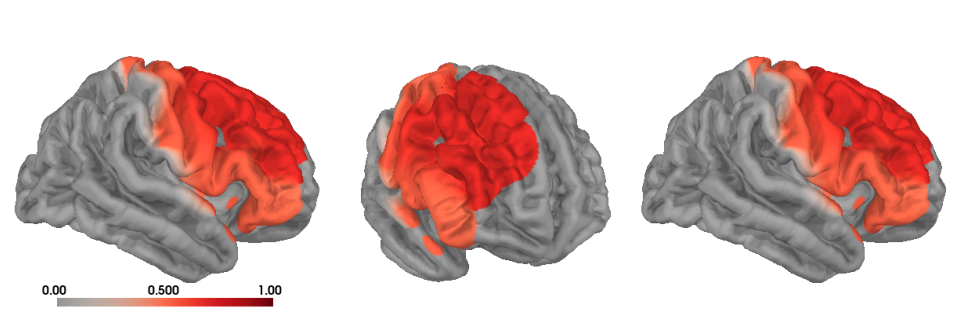

Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    160208 / 327684 non-zero vertices


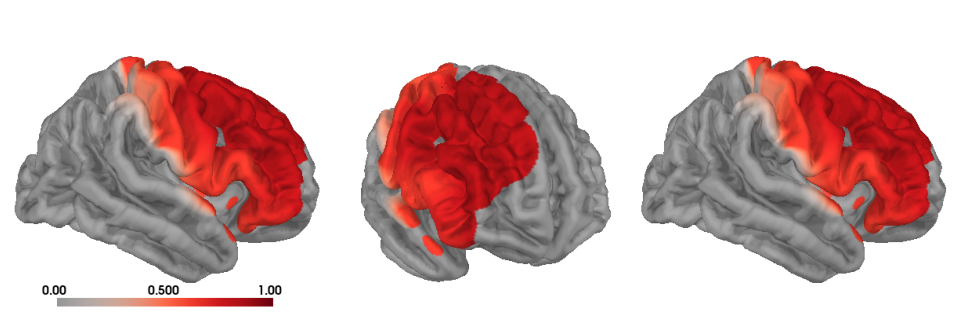

Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    160208 / 327684 non-zero vertices


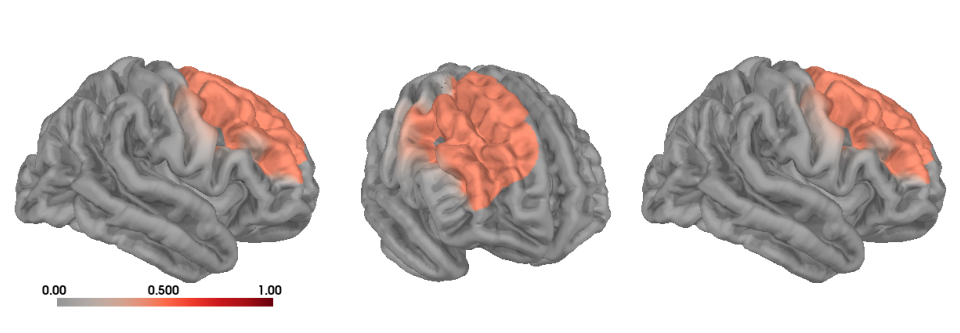

Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    160208 / 327684 non-zero vertices


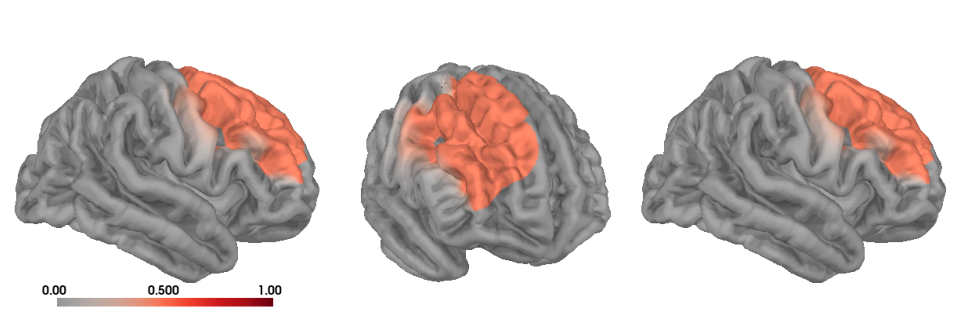

In [104]:
# unfuck the above

# Baseline theta predictors of WR changes -- ROI

import os
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np
import mne
from scipy.stats import zscore
from statsmodels.stats.multitest import multipletests  # ✅ For FDR correction

# Load the files
df_final = pd.read_csv('../../results_CI/df_combined_final_n10.csv')
behavior_df = pd.read_csv('../../results_CI/behavior_diff_data_CI.csv')
hemi_specificity_path = os.path.join("../../results_CI/specificity_with_optodes.csv")
hemi_specificity = pd.read_csv(hemi_specificity_path)
subjects_dir = '../../subjects_CI'

# Load raw file to extract channel locations
raw_file_path = f"../../processed_CI/113_3_002_long_hbo_final_CI_raw.fif"
raw = mne.io.read_raw_fif(raw_file_path, preload=True)
raw.load_data()

# **Step 0: Print Available Raw Channel Names BEFORE Cleaning**
picks = [ch for ch in raw.info['ch_names'] if ch.endswith(" hbo")]
raw.pick_channels(picks)

# **Step 1: Filter for hbdiff Chroma Data Only**
theta_df = df_final[df_final['Chroma'] == 'hbdiff'].copy()

# **Step 2: Standardize Channel Naming to End in " hbo"**
theta_df['ch_name'] = theta_df['ch_name'].str.replace(" hbdiff", " hbo", regex=False).str.strip()
hemi_specificity['ch_name'] = hemi_specificity['ch_name'].str.replace(" hbdiff", " hbo", regex=False).str.strip()
hemi_specificity['ch_name'] = hemi_specificity['ch_name'].str.replace(" hbr", " hbo", regex=False).str.strip()

# Convert subject to string for consistency
theta_df['subject'] = theta_df['subject'].astype(str)
behavior_df['subject'] = behavior_df['subject'].astype(str)

# **Step 3: Merge Theta Data with ROI Specificity Data**
theta_df = theta_df.merge(
    hemi_specificity[['ch_name', 'Hemisphere', 'Landmark']], 
    on='ch_name', 
    how='left'
)

# Drop rows where Hemisphere/Landmark is NaN
theta_df = theta_df.dropna(subset=['Hemisphere', 'Landmark'])

# Preserve original channel names in a new column
theta_df['original_ch_name'] = theta_df['ch_name']

# **Step 4: Create ROI Variable**
theta_df['ROI'] = theta_df['Hemisphere'] + '_' + theta_df['Landmark']
theta_df['ROI'] = theta_df['ROI'].str.replace(r'[^a-zA-Z0-9_]', '_', regex=True).str.strip('_')

# Remove outside brain ROIs
theta_df = theta_df[~theta_df['ROI'].isin(["Right_Brain_Outside", "Left_Brain_Outside"])]
num_rois = theta_df['ROI'].nunique()

# **Function to Perform Analysis and Plot Brain**
def perform_analysis(theta_df, behavior_df, conditions, response_vars, results_path):
    significant_models = []
    r_squared_values = []
    all_p_values = []

    # Compute z-score per channel within each condition and ROI
    theta_df['z_theta'] = theta_df.groupby(['Condition', 'ROI', 'ch_name'])['theta'].transform(zscore)

    # **Step 5: Aggregate by ROI (average across all ch_names per ROI)**
    roi_avg_df = (
        theta_df.groupby(['subject', 'Condition', 'ROI'])['z_theta']
        .mean()
        .reset_index()
        .rename(columns={'z_theta': 'z_theta_day1'})
    )

    # Merge with behavior data
    merged_df = pd.merge(roi_avg_df, behavior_df[['subject'] + response_vars], on='subject')

    for condition in conditions:
        for response_var in response_vars:
            df = merged_df[merged_df['Condition'] == condition][['ROI', response_var, 'z_theta_day1']].dropna()

            if df.empty:
                print(f"\n⚠️ WARNING: No data for condition {condition} - {response_var}")
                continue

            for roi in df['ROI'].unique():
                df_roi = df[df['ROI'] == roi]

                model = smf.ols(f"{response_var} ~ z_theta_day1", df_roi).fit()
                p_value = model.pvalues['z_theta_day1']
                r_squared = model.rsquared  # Extract R² value

                all_p_values.append(p_value)  # ✅ Store p-values for FDR correction
                
                if p_value < 0.05:  # Only save uncorrected p < 0.05
                    significant_models.append({
                        'ROI': roi, 'p_value': p_value, 'r_squared': r_squared,
                        'condition': condition, 'response_var': response_var
                    })

    # **Step 6: FDR Correction for p-values**
    p_values_corrected = multipletests(all_p_values, method='fdr_bh')[1]

    # Assign corrected p-values
    for i, entry in enumerate(significant_models):
        entry['p_value_fdr'] = p_values_corrected[i]

    # **Step 7: Save CSV**
    results_df = pd.DataFrame(significant_models)
    results_df.to_csv(os.path.join(results_path, "theta_analysis_results.csv"), index=False, header=True)

    # **Step 8: Plot Brain for R² Values**
    for condition in conditions:
        for response_var in response_vars:
            highlight_values = np.zeros(len(raw.ch_names))
            nonzero_count = 0

            for entry in significant_models:
                if entry['condition'] == condition and entry['response_var'] == response_var:
                    roi_name = entry['ROI']
                    r_squared = entry['r_squared']

                    matching_channels = theta_df[theta_df['ROI'] == roi_name]['original_ch_name'].unique()

                    for ch_name in matching_channels:
                        if ch_name in raw.ch_names:
                            idx = raw.ch_names.index(ch_name)
                            highlight_values[idx] = r_squared
                            nonzero_count += 1

            if nonzero_count == 0:
                continue

            # **Step 9: Create Evoked Array for Visualization**
            evoked = mne.EvokedArray(highlight_values[:, np.newaxis], raw.info)

            # Generate STC (Source Time Course) Data for Brain Visualization
            stc = mne.stc_near_sensors(
                evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
                distance=0.02, project=True, picks=np.arange(len(raw.ch_names)), subjects_dir=subjects_dir
            )

            # **Brain Plot Configuration**
            brain = stc.plot(
                hemi='both', views=['lat', 'frontal', 'lat'],
                cortex='low_contrast', time_viewer=False, show_traces=False,
                surface='pial', smoothing_steps=0, size=(1200, 400),
                clim=dict(kind='value', lims=[0, 0.5, 1]),  # ✅ R² color scale
                colormap='Reds', view_layout='horizontal',
                colorbar=True,
                time_label='', background='w',
                add_data_kwargs=dict(colorbar_kwargs=dict(
                    title_font_size=12, label_font_size=8, n_labels=3,
                    title=f' '
                )),
                subjects_dir=subjects_dir
            )

            # Capture the plot as an image in memory
            screenshot = brain.screenshot(time_viewer=False)
            brain.close()

            # Display the image in the composite figure
            fig, ax = plt.subplots(figsize=(10, 5))
            ax.imshow(screenshot)
            ax.axis('off')

            plt.tight_layout(rect=[0, 0, 1, 0.96])
            plt.savefig(f"{results_path}/brain_plot_r_squared_{condition}_{response_var}.png")
            plt.show()
            plt.close(fig)


# **Run Analysis**
perform_analysis(
    theta_df, 
    behavior_df, 
    conditions=['A', 'AV', 'V'], 
    response_vars=['AO_PH', 'AO_WR', 'TBW'],
    results_path="../../results_CI"
)





#####################################################################################

<h2>channel-based analysis code</h2>

In [ ]:
# Baseline theta vs. change in WR - channel

# Set your conditions, response variables, and chromas
conditions = ['A', 'AV', 'V']
response_vars = ['AO_WR', 'AV_WR', 'VO_WR']
chromas = ['hbdiff', 'hbo', 'hbr']
days = [1, 3]
proc_path = '../../processed_CI'
subjects_dir = '../../subjects_CI'
output_suffix = 'baseline_WR_correlation_CI'

# Load the MNE raw data
fname = op.join(proc_path, '111_1_001_long_hbo_final_CI_raw.fif')
use = mne.io.read_raw_fif(fname, preload=True)

# Prepare channels for consistency
new_ch_names = {}
seen_names = set()
for ch_name in use.info['ch_names']:
    new_name = ch_name.split(' ')[0]  # Clean channel names
    if new_name not in seen_names:
        new_ch_names[ch_name] = new_name
        seen_names.add(new_name)

use.rename_channels(new_ch_names)
use.pick_channels(list(new_ch_names.values()))  # Pick only renamed channels

theta_df['ch_name'] = theta_df['ch_name'].str.split(' ').str[0]  # Clean theta_df channels

print(theta_df['Chroma'].unique())  # Ensure chromas are as expected
print(theta_df['Condition'].unique())  # Ensure conditions are as expected


def perform_analysis(output_suffix, theta_df, behavior_df, days, chromas, conditions, response_vars):
    # Initialize a list to store significant models
    significant_models = []
    z_scores_dict = {}  # Dictionary to store z-scores by day, chroma, and channel

    # Initialize a dictionary to store p-values and model data by condition, response variable, chroma, and day
    all_p_values = {condition: {response_var: {chroma: {day: [] for day in days} for chroma in chromas} for response_var in response_vars} for condition in conditions}
    all_model_data = {condition: {response_var: {chroma: {day: [] for day in days} for chroma in chromas} for response_var in response_vars} for condition in conditions}

    for day in days:
        theta_df_filtered = theta_df[theta_df['day'] == day].copy()

        for chroma in chromas:
            theta_dataset = theta_df_filtered[theta_df_filtered['Chroma'] == chroma].copy()
            for condition in conditions:
                for response_var in response_vars:
                    theta_df_condition = theta_dataset[theta_dataset['Condition'] == condition]

                    # Pivot theta_df to have channel names as columns
                    theta_pivot = theta_df_condition.pivot_table(index=['subject', 'Condition'], columns='ch_name', values='theta').reset_index()
                    theta_pivot['subject'] = theta_pivot['subject'].astype(str)
                    
                    # Merge theta_df with behavior data
                    merged_df = pd.merge(theta_pivot, behavior_df[['subject', 'group', 'TBW', 'AO_WR', 'AV_WR', 'VO_WR', 'age', 'AO_WR_1', 'AV_WR_1', 'VO_WR_1', 'TBW_1']], on=['subject'])                    
                    channels = theta_df_condition['ch_name'].unique()
                    p_values = []  # Store p-values for FDR correction
                    model_data = []  # Store model data for each channel

                    for channel in channels:
                        df = merged_df[['subject', 'group', 'Condition', 'TBW', response_var, channel]].copy()
                        if df.empty:
                            continue  # Skip this channel if there is no data
                        # Fit the model
#                        for group in ['Post']:
#                            df_group = df[df['group'] == group].copy()
                        df_group = df.copy()
                        model = smf.ols(f"{response_var} ~ {channel}", df_group).fit()
                        r_sq = model.rsquared
                        p_value_channel = model.pvalues[channel]  # p-value for the channel
                        p_values.append(p_value_channel)
                        model_data.append((channel, model, r_sq, df_group))
                    if p_values:
                        rejected, p_values_corrected, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')
                        # Store z-scores for significant models after FDR correction
                        for i, (channel, model, r_sq, df_group) in enumerate(model_data):
                            if p_values_corrected[i] < 0.05:  # Significant after FDR
                                print(f"      Significant Channel: {channel}, Corrected p-value: {p_values_corrected[i]}, R^2: {r_sq}")
                                channel_hbo = channel + ' ' + chroma
                                z_scores = zscore(df_group[channel])  # Compute z-scores

                                # Store the z-scores in the dictionary
                                z_scores_dict[(day, chroma, condition, channel_hbo)] = z_scores

                                # Log the significant model
                                significant_models.append({
                                    'day': day, 'chroma': chroma, 'condition': condition, 'channel': channel_hbo,
                                    'r_squared': r_sq, 'p_value': p_values[i], 'p_value_corrected': p_values_corrected[i],
                                    'z_scores': z_scores
                                })

                                # Plot the significant results
                                import matplotlib as mpl
                                mpl.rcParams['font.family'] = 'Arial'
                                plt.figure(figsize=(8, 6))
                                group_colors = {'Pre': '#AA4A44', 'Post': 'black'}

                                # Scatter plot and regression line for each group
                                #print(df.columns)
                                #df_pre = df[(df['group'] == 'Pre')].copy()  # Extract 'Pre' data for this channel
                                #df_pre['color'] = df_pre['group'].map(group_colors)
                                #if not df_pre.empty:
                                #    plt.scatter(df_pre[channel] * 1e6, df_pre[response_var], c=df_pre['color'], s=80, label='Pre')

                                # Scatter plot and regression line for 'Post' group (use df_group for regression line)
                                if not df_group.empty:
                                    print(f"Available columns in df_post: {df_group.columns}")
                                    df_group.loc[:, 'color'] = df_group['group'].map(group_colors)
                                    plt.scatter(df_group[channel] * 1e6, df_group[response_var], c=df_group['color'], s=80)
                                    
                                    # Fit model for 'Post' group only
                                    model_post = smf.ols(f"{response_var} ~ {channel}", df_group).fit()
                                    plt.plot(df_group[channel] * 1e6, model_post.predict(df_group), color='black', linewidth=2)

                                # Customize axes and plot aesthetics
                                plt.gca().spines['top'].set_visible(False)
                                plt.gca().spines['right'].set_visible(False)
                                plt.gca().spines['left'].set_linewidth(1)
                                plt.gca().spines['bottom'].set_linewidth(1)
                                plt.axhline(0, color='black', linestyle=':', linewidth=1)  # Dotted line at y=0
                                plt.xlabel(f'[HbDiff] on Day 1', fontsize=18, color='black')
                                plt.ylabel('Word Recognition Δ', fontsize=18, color='black')
                                plt.title(f'Baseline Channel {channel} {condition} Activity and \nChanges in {response_var} Word Recognition', fontsize=18, color='black', fontweight='bold')
    #                            plt.xlim(-0.8, 1.1)
    #                            plt.xticks(np.arange(-0.8, 1.3, 0.4), fontsize=16, color='dimgray')
                                plt.yticks(fontsize=16, color='dimgray')
                                plt.tick_params(axis='x', which='both', bottom=False, top=False)
                                plt.tick_params(axis='y', which='both', left=False, right=False)
                                plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, fontsize=18)

                                plt.tight_layout()
                                plt.savefig(f'{results_path}/baseline_WR_correlation_{chroma}_{condition}_{response_var}_{channel}.png', dpi=300, bbox_inches='tight')
                                plt.close()

    return significant_models, z_scores_dict

significant_models, z_scores_dict = perform_analysis(output_suffix, theta_df, behavior_df, days, chromas, conditions, response_vars)


In [ ]:
# change WR vs change theta -- channel

import os
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib as mpl
from statsmodels.stats.multitest import multipletests

conditions = ['A', 'AV', 'V']
response_vars = ['AO_WR', 'AV_WR', 'VO_WR', 'TBW']
chromas = ['hbo', 'hbr', 'hbdiff']
days = [1, 3]
theta_df['ch_name'] = theta_df['ch_name'].str.split(' ').str[0]  # Clean channel names

def perform_analysis(theta_df, behavior_df, chromas, conditions, response_vars, results_path):
    significant_models = []

    # Calculate theta_diff (Day 3 - Day 1)
    day_1 = theta_df[theta_df['day'] == 1].copy().rename(columns={'theta': 'theta_day1'})
    day_3 = theta_df[theta_df['day'] == 3].copy().rename(columns={'theta': 'theta_day3'})

    # Merge Day 1 and Day 3 without 'group'
    theta_diff_df = pd.merge(
        day_1,
        day_3[['subject', 'Condition', 'Chroma', 'ch_name', 'theta_day3']],
        on=['subject', 'Condition', 'Chroma', 'ch_name'],
        how='inner'
    )
    theta_diff_df['theta_diff'] = theta_diff_df['theta_day3'] - theta_diff_df['theta_day1']

    # Perform analysis for each chroma, condition, and response variable
    for chroma in chromas:
        theta_dataset = theta_diff_df[theta_diff_df['Chroma'] == chroma].copy()
        for condition in conditions:
            for response_var in response_vars:
                theta_df_condition = theta_dataset[theta_dataset['Condition'] == condition]

                # Pivot theta_diff_df to have channel names as columns
                theta_pivot = theta_df_condition.pivot_table(index=['subject', 'Condition'], columns='ch_name', values='theta_diff').reset_index()
                theta_pivot['subject'] = theta_pivot['subject'].astype(str)

                # Merge with behavior data (without 'group')
                merged_df = pd.merge(
                    theta_pivot,
                    behavior_df[['subject', 'TBW', 'AO_WR', 'AV_WR', 'VO_WR', 'age', 'AO_WR_1', 'AV_WR_1', 'VO_WR_1', 'TBW_1']],
                    on=['subject']
                )

                channels = theta_df_condition['ch_name'].unique()
                p_values = []  # Store p-values for FDR correction
                model_data = []  # Store model data for each channel

                for channel in channels:
                    df = merged_df[[channel, response_var]].dropna()
                    if df.empty:
                        continue  # Skip if no data

                    # Fit the model
                    model = smf.ols(f"{response_var} ~ {channel}", df).fit()
                    r_sq = model.rsquared
                    p_value_channel = model.pvalues[channel]  # p-value for the channel

                    p_values.append(p_value_channel)
                    model_data.append((channel, model, r_sq, df))

                if p_values:
                    rejected, p_values_corrected, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')

                    # Store significant models and save plots
                    for i, (channel, model, r_sq, df) in enumerate(model_data):
                        if p_values_corrected[i] < 0.05:  # Significant after FDR
                            print(f"Significant Channel: {channel}, Corrected p-value: {p_values_corrected[i]}, R^2: {r_sq}")

                            # Save model info
                            significant_models.append({
                                'chroma': chroma,
                                'condition': condition,
                                'response_var': response_var,
                                'channel': channel,
                                'r_squared': r_sq,
                                'p_value': p_values[i],
                                'p_value_corrected': p_values_corrected[i]
                            })

                            # Plot the significant results
                            mpl.rcParams['font.family'] = 'Arial'
                            plt.figure(figsize=(8, 6))

                            # Scatter plot
                            plt.scatter(df[channel] * 1e6, df[response_var], color='black', s=80, alpha=0.7)

                            # Regression line
                            plt.plot(df[channel] * 1e6, model.predict(df), color='black', linewidth=2)

                            # Customize aesthetics
                            plt.gca().spines['top'].set_visible(False)
                            plt.gca().spines['right'].set_visible(False)
                            plt.gca().spines['left'].set_linewidth(1)
                            plt.gca().spines['bottom'].set_linewidth(1)
                            plt.axhline(0, color='black', linestyle=':', linewidth=1)
                            plt.xlabel(f'[HbO] Δ', fontsize=18, color='black')
                            plt.ylabel('Word Recognition Δ', fontsize=18, color='black')
                            plt.title(f'Changes in {channel} Activity and \nChanges in {response_var} Word Recognition', 
                                      fontsize=18, color='black', fontweight='bold')
                            plt.yticks(fontsize=16, color='dimgray')
                            plt.tick_params(axis='x', which='both', bottom=False, top=False)
                            plt.tick_params(axis='y', which='both', left=False, right=False)
                            plt.tight_layout()

                            # Save plot
                            plot_filename = os.path.join(results_path, f"changes_correlations_{channel}_{response_var}_{condition}_{chroma}.png")
                            plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
                            plt.close()
    
    # Export results to CSV
    output_filename = os.path.join(results_path, "changes_correlations.csv")
    pd.DataFrame(significant_models).to_csv(output_filename, index=False)
    print(f"Saved significant models to {output_filename}")


# Run the analysis (no group distinction)
perform_analysis(theta_df, behavior_df, chromas, conditions, response_vars, results_path)


Code below is still in progress...

Opening raw data file ../../processed/205_1_001_long_hbo_final_raw.fif...
    Range : 0 ... 4171 =      0.000 ...   867.568 secs
Ready.
Reading 0 ... 4171  =      0.000 ...   867.568 secs...


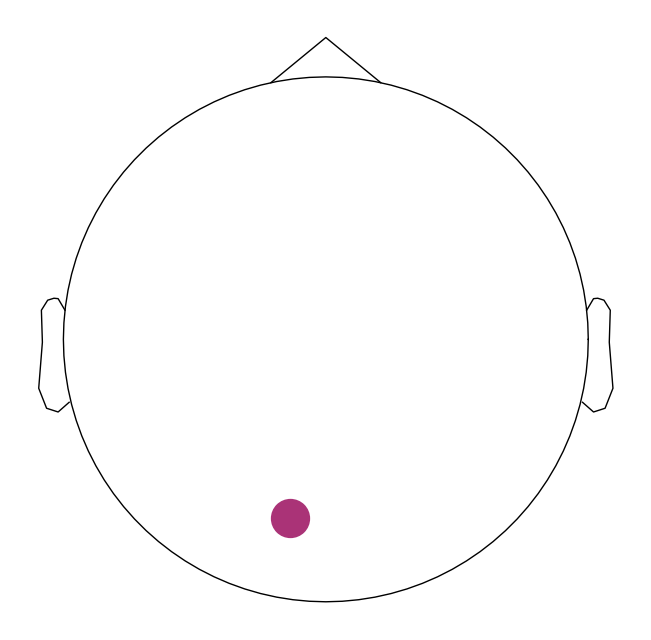

In [2]:
# Plot sensors of interest

import mne
import matplotlib.pyplot as plt
import os.path as op

# Use the info from your existing data
proc_path = '../../processed'
fname = op.join(proc_path, f'205_1_001_long_hbo_final_raw.fif')
use = mne.io.read_raw_fif(fname, preload=True)
use.load_data()
info = use.copy().info

# Specify the names of the sensors you want to plot
selected_sensors = ['S25_D14 hbo']
valid_sensors = [sensor for sensor in selected_sensors if sensor in info['ch_names']]

if not valid_sensors:
    print("No valid sensors selected for plotting.")
else:
    # Increase the font size for sensor names
    plt.rcParams.update({'font.size': 20})  # Set the desired font size

    # Pick only the selected channels
    info_picked = mne.pick_info(info, mne.pick_channels(info['ch_names'], valid_sensors))
    info_picked.rename_channels({ch: '  ' + ch for ch in info_picked['ch_names']})

    # Plot the sensors manually with blue circles
    fig = mne.viz.plot_sensors(info_picked, kind='topomap', show_names=False, pointsize=800, linewidth=0)

    plt.show()



Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...


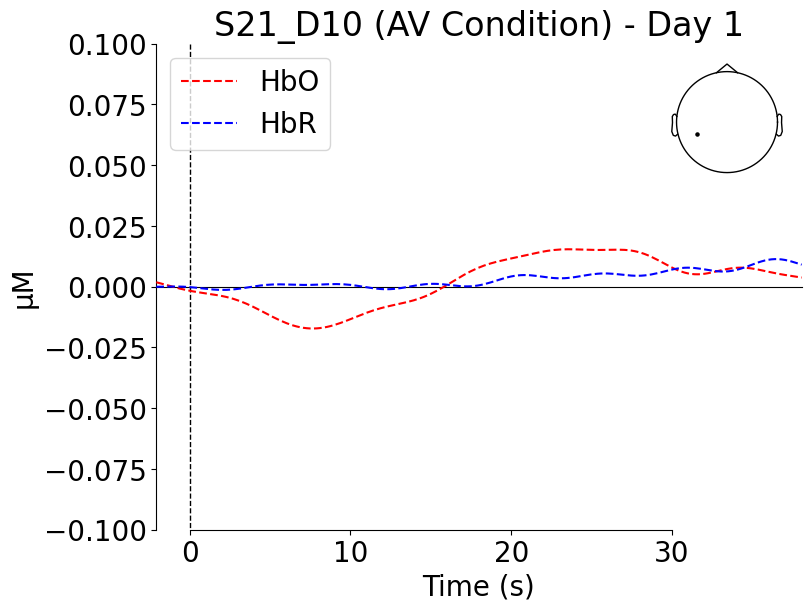

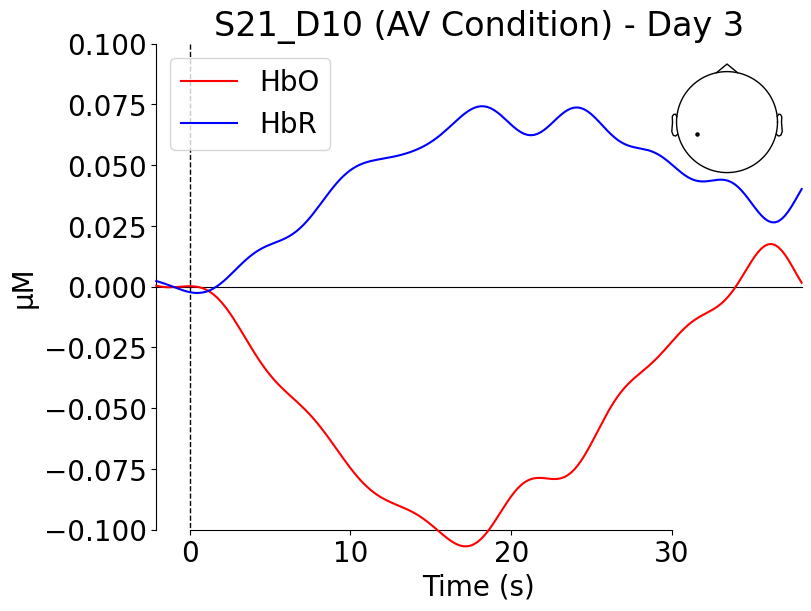

All participants were included in the Day 1 analysis.
All participants were included in the Day 3 analysis.


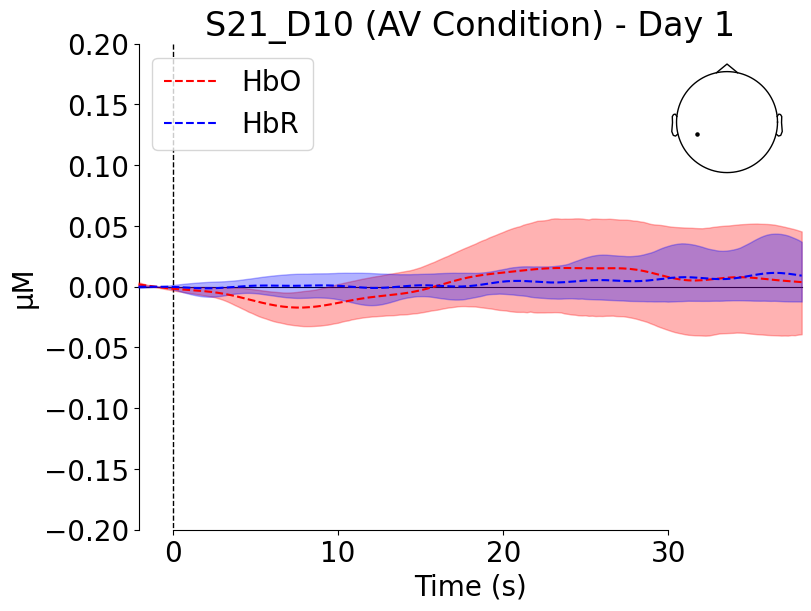

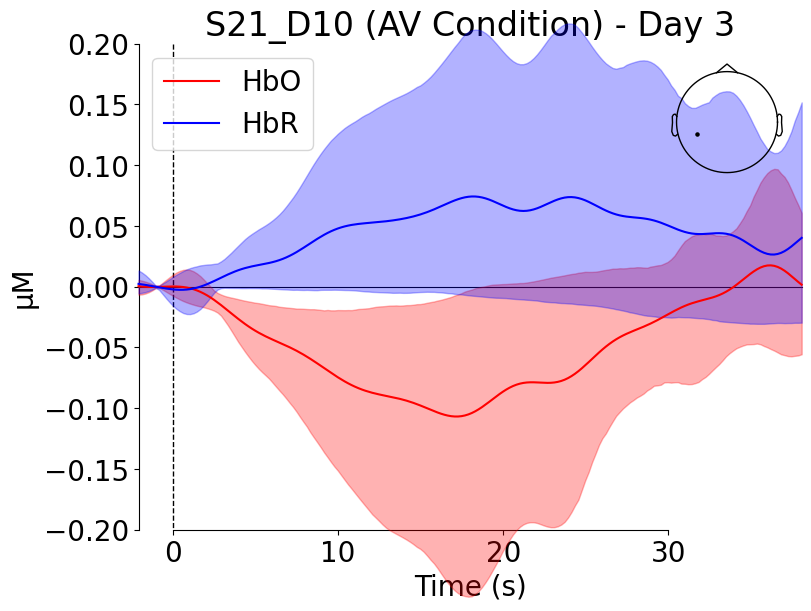

[<Figure size 800x600 with 2 Axes>]

In [3]:
# Plot some waveforms

import mne
import os.path as op
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load subject group mapping
subject_group_mapping = pd.read_csv('../../subject_group_mapping.csv')
subject_group_mapping['Subject'] = subject_group_mapping['Subject'].astype(str).str.strip().str.split('.').str[0]
subject_to_group = dict(zip(subject_group_mapping['Subject'], subject_group_mapping['Group']))

# Ensure all subjects are in string format without decimals
subjects = subject_group_mapping['Subject'].tolist()
#subjects = [subject for subject in subjects if subject not in ['202', '203', '204', '206', '214', '221', '223', '226', '233']]

# Define the subjects in the 'trained' group
trained_subjects = [subject for subject in subjects if subject_to_group[subject] == 'trained']

# Specify the channel of interest
channel_of_interest = 'S21_D10'
condition = 'AV'

# Initialize the dictionaries to store evoked data for averaging and plotting
evoked_dict_day1 = {'HbO': [], 'HbR': []}
evoked_dict_day3 = {'HbO': [], 'HbR': []}

# Loop over subjects and load their evoked data
for subject in trained_subjects:
    for day in ['1', '3']:
        # Define the filename
        fname = op.join(proc_path, f'{subject}_{day}_final-ave.fif')
        
        # Load the evoked data
        evokeds = mne.read_evokeds(fname, condition=condition, baseline=(None, 0), verbose=False)
                
        # Pick the HbO and HbR data for the channel of interest
        evoked_hbo = evokeds.copy().pick([f'{channel_of_interest} hbo'])
        evoked_hbr = evokeds.copy().pick([f'{channel_of_interest} hbr'])
        
        evoked_hbo.rename_channels(lambda x: x[:-4])
        evoked_hbr.rename_channels(lambda x: x[:-4])
        
        # Check if both HbO and HbR data exist for this subject and day
        if len(evoked_hbo.ch_names) == 1 and len(evoked_hbr.ch_names) == 1:
            # Store in the appropriate evoked dictionary
            if day == '1':
                evoked_dict_day1['HbO'].append(evoked_hbo)
                evoked_dict_day1['HbR'].append(evoked_hbr)
            elif day == '3':
                evoked_dict_day3['HbO'].append(evoked_hbo)
                evoked_dict_day3['HbR'].append(evoked_hbr)

# Compute grand average for Day 1 and Day 3
grand_avg_day1_hbo = mne.grand_average(evoked_dict_day1['HbO'])
grand_avg_day1_hbr = mne.grand_average(evoked_dict_day1['HbR'])
grand_avg_day3_hbo = mne.grand_average(evoked_dict_day3['HbO'])
grand_avg_day3_hbr = mne.grand_average(evoked_dict_day3['HbR'])

# Prepare the grand average dictionary for plotting
grand_avg_dict_day1 = {'HbO': grand_avg_day1_hbo, 'HbR': grand_avg_day1_hbr}
grand_avg_dict_day3 = {'HbO': grand_avg_day3_hbo, 'HbR': grand_avg_day3_hbr}

# Define the colors and styles
color_dict_day1 = {'HbO': 'red', 'HbR': 'blue'}
color_dict_day3 = {'HbO': 'red', 'HbR': 'blue'}
styles_dict_day1 = {'HbO': {'linestyle': '--'}, 'HbR': {'linestyle': '--'}}
styles_dict_day3 = {'HbO': {'linestyle': '-'}, 'HbR': {'linestyle': '-'}}

# Plot for Day 1 using the grand average
mne.viz.plot_compare_evokeds(
    grand_avg_dict_day1,
    ci=0.95, colors=color_dict_day1, styles=styles_dict_day1,
    title=f'{channel_of_interest} ({condition} Condition) - Day 1', show=True,
    truncate_xaxis=(-2, 15),  # This line sets the x-axis limits
    ylim=dict(hbo=(-0.10, 0.10))  # This line sets the y-axis limits
)

# Plot for Day 3 using the grand average
mne.viz.plot_compare_evokeds(
    grand_avg_dict_day3,
    ci=0.95, colors=color_dict_day3, styles=styles_dict_day3,
    title=f'{channel_of_interest} ({condition} Condition) - Day 3', show=True,
    truncate_xaxis=(-2, 15),  # This line sets the x-axis limits
    ylim=dict(hbo=(-0.10, 0.10))  # This line sets the y-axis limits
)

# Initialize the dictionaries to store evoked data for plotting
evoked_dict_day1 = {'HbO': [], 'HbR': []}
evoked_dict_day3 = {'HbO': [], 'HbR': []}

# Loop over subjects and load their evoked data
for subject in trained_subjects:
    for day in ['1', '3']:
        # Define the filename
        fname = op.join(proc_path, f'{subject}_{day}_final-ave.fif')
        
        # Load the evoked data
        evokeds = mne.read_evokeds(fname, condition=condition, baseline=(None, 0), verbose=False)
                
        # Pick the HbO and HbR data for the channel of interest
        evoked_hbo = evokeds.copy().pick([f'{channel_of_interest} hbo'])
        evoked_hbr = evokeds.copy().pick([f'{channel_of_interest} hbr'])
        
        evoked_hbo.rename_channels(lambda x: x[:-4])
        evoked_hbr.rename_channels(lambda x: x[:-4])
        
        # Check if both HbO and HbR data exist for this subject and day
        if len(evoked_hbo.ch_names) == 1 and len(evoked_hbr.ch_names) == 1:
            # Store in the appropriate evoked dictionary
            if day == '1':
                evoked_dict_day1['HbO'].append(evoked_hbo)
                evoked_dict_day1['HbR'].append(evoked_hbr)
            elif day == '3':
                evoked_dict_day3['HbO'].append(evoked_hbo)
                evoked_dict_day3['HbR'].append(evoked_hbr)

# Check if all participants were included
expected_subjects = len(trained_subjects)
actual_subjects_day1 = len(evoked_dict_day1['HbO'])  # Same number for HbO and HbR
actual_subjects_day3 = len(evoked_dict_day3['HbO'])  # Same number for HbO and HbR

if actual_subjects_day1 != expected_subjects:
    print(f"Warning: Only {actual_subjects_day1} out of {expected_subjects} subjects were included in the Day 1 analysis.")
else:
    print("All participants were included in the Day 1 analysis.")

if actual_subjects_day3 != expected_subjects:
    print(f"Warning: Only {actual_subjects_day3} out of {expected_subjects} subjects were included in the Day 3 analysis.")
else:
    print("All participants were included in the Day 3 analysis.")

# Define the colors and styles
color_dict_day1 = {'HbO': 'red', 'HbR': 'blue'}
color_dict_day3 = {'HbO': 'red', 'HbR': 'blue'}
styles_dict_day1 = {'HbO': {'linestyle': '--'}, 'HbR': {'linestyle': '--'}}
styles_dict_day3 = {'HbO': {'linestyle': '-'}, 'HbR': {'linestyle': '-'}}

# Plot for Day 1 using the individual evoked responses
mne.viz.plot_compare_evokeds(
    {'HbO': evoked_dict_day1['HbO'], 'HbR': evoked_dict_day1['HbR']},
    ci=0.95, colors=color_dict_day1, styles=styles_dict_day1,
    title=f'{channel_of_interest} ({condition} Condition) - Day 1', show=True,
    truncate_xaxis=(-2, 15),  # This line sets the x-axis limits
    ylim=dict(hbo=(-0.20, 0.20))  # This line sets the y-axis limits
)

# Plot for Day 3 using the individual evoked responses
mne.viz.plot_compare_evokeds(
    {'HbO': evoked_dict_day3['HbO'], 'HbR': evoked_dict_day3['HbR']},
    ci=0.95, colors=color_dict_day3, styles=styles_dict_day3,
    title=f'{channel_of_interest} ({condition} Condition) - Day 3', show=True,
    truncate_xaxis=(-2, 15),  # This line sets the x-axis limits
    ylim=dict(hbo=(-0.20, 0.20))  # This line sets the y-axis limits
)


In [4]:
# Compare thetas in 2 specific channels

# Filter data for the specific channels you want to compare
channels_to_analyze = ['S19_D6', 'S15_D14']

from statsmodels.tools.sm_exceptions import ValueWarning
warnings.filterwarnings("ignore", category=ValueWarning) # type: ignore
warnings.filterwarnings("ignore", category=UserWarning) # type: ignore

# Load the datasets
behavior_df = pd.read_csv(behavior_file)
behavior_df['subject'] = behavior_df['subject'].astype(str)

theta_df_filtered = df_final.copy()
theta_df_filtered['subject'] = theta_df_filtered['subject'].astype(str)

# Pivot table to get both Day 1 theta and theta_diff (Day 3 - Day 1)
theta_df_filtered = theta_df_filtered.pivot_table(index=['subject', 'group', 'Condition', 'Chroma', 'ch_name'], columns='day', values='theta').reset_index()
theta_df_filtered['theta_diff'] = theta_df_filtered[3] - theta_df_filtered[1]  # Calculate theta_diff
theta_df_filtered['theta_baseline'] = theta_df_filtered[1]  # Baseline theta (Day 1)
theta_df_filtered = theta_df_filtered[theta_df_filtered['group'] != 'unknown']


def perform_channel_comparison(group, output_suffix):
    # Initialize a list to store significant models
    theta_df_filtered['ch_name'] = theta_df_filtered['ch_name'].str.split(' ').str[0]
    significant_models = []
    
    # Iterate over each condition and chroma
    for chroma in chromas:
        all_p_values = []
        model_data = []

        for condition in conditions:
            print(f"\nStarting analysis for condition: {condition}, chroma: {chroma}, group: {group}\n")
            # Filter the dataset for the current condition and chroma
            theta_df_condition = theta_df_filtered[(theta_df_filtered['Chroma'] == chroma) & (theta_df_filtered['Condition'] == condition)]
            
            # Pivot the theta_df to have channel names as columns
            theta_pivot = theta_df_condition.pivot_table(index=['subject', 'group'], columns='ch_name', values=['theta_diff', 'theta_baseline'])
            theta_pivot.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col for col in theta_pivot.columns.values]  # Flatten the MultiIndex
            
            # Reset the index to make 'group' a column again
            theta_pivot.reset_index(inplace=True)

            # Ensure both channels are in the pivoted dataframe
            if f'theta_diff_S19_D6' in theta_pivot.columns and f'theta_diff_S15_D14' in theta_pivot.columns:
                df = theta_pivot[[f'theta_diff_S19_D6', f'theta_diff_S15_D14', f'theta_baseline_S19_D6', f'theta_baseline_S15_D14', 'group']].dropna()
                
                if df.empty:
                    print("  No data available for the selected channels, skipping.")
                    continue  # Skip this condition if there is no data

                # Perform regression analysis for S19_D6 vs. S20_D10
                model = smf.ols(f"theta_diff_S15_D14 ~ theta_diff_S19_D6", df[df['group'] == group]).fit()
                r_sq = model.rsquared
                p_value_channel = model.pvalues[f'theta_diff_S19_D6']

                # Collect p-values and models for FDR correction
                all_p_values.append(p_value_channel)
                model_data.append((condition, 'S19_D6_vs_S15_D14', r_sq, p_value_channel, model, chroma, df))
            else:
                print(f"  One or both channels S19_D6 and S15_D14 are missing for condition {condition}, skipping.")
                continue  # Skip this condition if there is no data

        # Apply FDR correction
        if len(all_p_values) > 0:
            rejected, p_values_corrected, _, _ = multipletests(all_p_values, alpha=0.05, method='fdr_bh')

        # Filter results based on FDR corrected p-values and plot only if significant
        for i, (condition, comparison, r_sq, p_value, model, chroma, df) in enumerate(model_data):
            if p_values_corrected[i] < 0.05:
                print(f"Comparison: {comparison}, {condition}, chroma: {chroma}, group: {group}")
                print(f"   p-value: {p_value}, corrected p-value: {p_values_corrected[i]}, R-squared: {r_sq}\n")
                
                significant_models.append({
                    'Condition': condition,
                    'Comparison': comparison,
                    'R-squared': r_sq,
                    'P-value': p_value,
                    'P-value Corrected': p_values_corrected[i],
                    'Model Summary': model.summary().as_text(),
                    'Chroma': chroma,
                    'Group': group
                })

                # Plot the significant results
                plt.figure(figsize=(8, 6))
                sns.scatterplot(x=df[f'theta_diff_S19_D6'], y=df[f'theta_diff_S15_D14'], hue=df['group'], palette=['#92b6f0', 'gray'], s=100)
                sns.lineplot(x=df[f'theta_diff_S19_D6'], y=model.predict(df), color='black', linewidth=2)

                xlabel = f'{chroma.upper()} Change in S19_D6 (Day 3 - Day 1)'
                ylabel = f'{chroma.upper()} Change in S15_D14 (Day 3 - Day 1)'
                plt.xlabel(xlabel, fontsize=16)
                plt.ylabel(ylabel, fontsize=16)
                plt.title(f'Comparison of {xlabel} and {ylabel} in {condition} condition', fontsize=16)
                plt.legend(title='Group', loc='upper right')
                plt.savefig(op.join(results_path, f'{output_suffix}__{group}_{chroma}_{condition}_S19_D6_vs_S15_D14_plot.png'))
                plt.close()

    # Save significant models to CSV
    if significant_models:
        significant_models_df = pd.DataFrame(significant_models).sort_values(by='R-squared', ascending=False)
        csv_file = op.join(results_path, f'{output_suffix}_{group}_models.csv')
        if not op.isfile(csv_file):
            significant_models_df.to_csv(csv_file, index=False, mode='w')
        else:
            significant_models_df.to_csv(csv_file, index=False, mode='a', header=False)
    else:
        print(f'No significant models found for group {group}')

# Perform the comparison analysis for the trained group
perform_channel_comparison('trained', 'S19_D6_vs_S15_D14_comparison')



KeyError: 'group'

In [ ]:
# Run paired t-test over days and plot changes over time, plot R^2 values onto brain

# Load the final combined dataframe
#df_final = pd.read_csv(op.join(results_path, f'df_combined_final_cha_{output_suffix}.csv'))
conditions = ['AV']
groups = ['trained']
chromas = ['hbdiff']

df_final['ch_name'] = df_final['ch_name'].str.split(' ').str[0]
fname = op.join(proc_path, f'205_1_001_long_hbo_final_raw.fif')
use = mne.io.read_raw_fif(fname, preload=True)
use.load_data()
new_ch_names = {}
seen_names = set()
for ch_name in use.info['ch_names']:
    new_name = ch_name.split(' ')[0]
    if new_name not in seen_names:
        new_ch_names[ch_name] = new_name
        seen_names.add(new_name)

use.rename_channels(new_ch_names)
use = use.pick_channels(list(new_ch_names.values()))

# Perform analysis for each group and Chroma
for group in groups:
    for chroma in chromas:
        # Prepare figure for composite plots
        fig, axes = plt.subplots(1, len(conditions), figsize=(15, 5))
        for idx, condition in enumerate(conditions):
            # Filter data for day 1 and day 3 for the specific group and Chroma
            df_day1 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 1").copy()
            df_day3 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 3").copy()

            # Ensure ch_name and Condition columns are of the same data type
            df_day1['ch_name'] = df_day1['ch_name'].astype(str)
            df_day1['Condition'] = df_day1['Condition'].astype(str)
            df_day3['ch_name'] = df_day3['ch_name'].astype(str)
            df_day3['Condition'] = df_day3['Condition'].astype(str)

            # Set index and sort
            df_day1 = df_day1.set_index(['subject', 'group', 'ch_name', 'Condition', 'Chroma']).sort_index()
            df_day3 = df_day3.set_index(['subject', 'group', 'ch_name', 'Condition', 'Chroma']).sort_index()

            # Merge dataframes to align day 1 and day 3 data
            df_merged = df_day1[['theta']].rename(columns={'theta': 'theta_day1'}).merge(
                df_day3[['theta']].rename(columns={'theta': 'theta_day3'}),
                left_index=True, right_index=True)

            # Calculate the difference and z-score
            df_merged['theta_diff'] = df_merged['theta_day3'] - df_merged['theta_day1']
            df_merged['z'] = zscore(df_merged['theta_diff'])

            # Perform paired t-test for each channel and condition across subjects
            t_stats = []
            p_values = []
            ch_names = []
            condition_list = []

            for (ch_name, cond), group_df in df_merged.groupby(['ch_name', 'Condition']):
                t_stat, p_value = ttest_rel(group_df['theta_day1'], group_df['theta_day3'])
                t_stats.append(t_stat)
                p_values.append(p_value)
                ch_names.append(ch_name)
                condition_list.append(cond)

            # Create a results DataFrame
            results_df = pd.DataFrame({
                'ch_name': ch_names,
                'Condition': condition_list,
                't_stat': t_stats,
                'p_value': p_values
            })

            # Combine with z-score data
            z_scores = df_merged.groupby(['ch_name', 'Condition'])['z'].mean().reset_index()
            
            # Ensure consistent data types before merging
            z_scores['ch_name'] = z_scores['ch_name'].astype(str)
            z_scores['Condition'] = z_scores['Condition'].astype(str)
            results_df['ch_name'] = results_df['ch_name'].astype(str)
            results_df['Condition'] = results_df['Condition'].astype(str)

            results_df = results_df.merge(z_scores, on=['ch_name', 'Condition'])

            # Correct for multiple comparisons
            print(f'Correcting for {len(results_df["p_value"])} comparisons using FDR')
            _, results_df['P_fdr'] = mne.stats.fdr_correction(results_df['p_value'], method='indep')
            results_df['SIG'] = results_df['P_fdr'] < 0.05
            
            # Print significant results
            significant_results = results_df.loc[results_df.SIG == True]
            print(significant_results)

            # Prepare data for brain plots
            ch_of_interest = use.pick_channels([ch_name for ch_name in use.info['ch_names']])
            info_of_interest = ch_of_interest.info

            zs = {}
            condition_data = results_df[(results_df['Condition'] == condition)]
                        
            zs[condition] = np.array([
                condition_data.loc[(condition_data['ch_name'] == ch_name), 'z'].values[0]

                if not condition_data.loc[(condition_data['ch_name'] == ch_name), 'z'].empty and condition_data.loc[(condition_data['ch_name'] == ch_name), 'P_fdr'].values[0] < 0.05
                else 0
                for ch_name in condition_data['ch_name']
            ])

            highlight_channels = ['S15_D14', 'S19_D4', 'S21_D10']  # Specify the channels you want to highlight
            highlight_values = np.zeros(len(info_of_interest['ch_names']))
            highlight_values_dict = {
                'S15_D14': 0.7367077245612972,  # R² for S15_D14 hbo
                'S19_D4': 0.8657075815562162,   # R² for S19_D4 hbo
                'S21_D10': 0.851818535397406    # R² for S21_D10 hbo
            }

            # Set the values for the highlight channels
            for ch_name, highlight_value in highlight_values_dict.items():
                if ch_name in info_of_interest['ch_names']:
                    idx = info_of_interest['ch_names'].index(ch_name)
                    highlight_values[idx] = highlight_value

            # Create an EvokedArray for each condition
            evoked = mne.EvokedArray(highlight_values[:, np.newaxis], info_of_interest)
            picks = np.arange(len(info_of_interest['ch_names']))

            # Create the source time course (STC) and highlight specific channels
            stc = mne.stc_near_sensors(
                evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
                distance=0.02, project=True, picks=picks, subjects_dir=subjects_dir)

            # Plot the brain and capture the image in-memory
            brain = stc.plot(hemi='both', views=['lat', 'frontal', 'lat'],
                             cortex='low_contrast', time_viewer=False, show_traces=False,
                             surface='pial', smoothing_steps=0, size=(1200, 400),
                             clim=dict(kind='value', lims=[0, 0.5, 1.0]),
                             colormap='Reds', view_layout='horizontal',
                             colorbar=(0, 1), time_label='', background='w',
                             brain_kwargs=dict(units='m'),
                             add_data_kwargs=dict(colorbar_kwargs=dict(
                                 title_font_size=12, label_font_size=8, n_labels=3,
                                 title='   ')), subjects_dir=subjects_dir)
            brain.show_view('lat', hemi='lh', row=0, col=0)
            brain.show_view(azimuth=270, elevation=90, row=0, col=1)
            brain.show_view('lat', hemi='rh', row=0, col=2)

            # Capture the plot as an image in memory
            screenshot = brain.screenshot(time_viewer=False)
            brain.close()

            # Display the image in the composite figure
            ax = axes
            ax.imshow(screenshot)
            ax.axis('off')
            ax.set_title(f'{group.capitalize()} - Condition {condition} ({chroma})', fontsize=18)

            del df_day1, df_day3, df_merged, t_stats, p_values, ch_names, condition_list, results_df, z_scores
            gc.collect()  #

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.savefig(op.join(results_path, f'{group}_{chroma}_composite_brain_plots_FDRinsig.png'))
        plt.show()
        plt.close(fig)

        del fig, axes, ch_of_interest, info_of_interest, evoked, stc, brain, screenshot
        gc.collect()  #


In [ ]:
# Plot changes in theta activity across channels x condition x group

conditions = ['A','AV','V']
groups = ['trained', 'control']
chromas = ['hbdiff']

# Perform analysis for each group and Chroma
for group in groups:
    for chroma in chromas:
        # Prepare figure for composite plots
        fig, axes = plt.subplots(1, len(conditions), figsize=(15, 5))
        axes = np.atleast_1d(axes)  # Ensure axes is an array to avoid indexing issues

        for idx, condition in enumerate(conditions):
            # Filter data for day 1 and day 3 for the specific group and Chroma
            df_day1 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 1 and Condition == '{condition}'").copy()
            df_day3 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 3 and Condition == '{condition}'").copy()

            # Ensure ch_name and Condition columns are of the same data type
            df_day1['ch_name'] = df_day1['ch_name'].astype(str)
            df_day3['ch_name'] = df_day3['ch_name'].astype(str)

            # Set index and sort
            df_day1 = df_day1.set_index(['subject', 'group', 'ch_name', 'Condition', 'Chroma']).sort_index()
            df_day3 = df_day3.set_index(['subject', 'group', 'ch_name', 'Condition', 'Chroma']).sort_index()

            # Merge dataframes to align day 1 and day 3 data
            df_merged = df_day1[['theta']].rename(columns={'theta': 'theta_day1'}).merge(
                df_day3[['theta']].rename(columns={'theta': 'theta_day3'}),
                left_index=True, right_index=True)

            # Calculate the difference in theta (Day 3 - Day 1)
            df_merged['theta_diff'] = df_merged['theta_day3'] - df_merged['theta_day1']

            # Calculate z-scores
            df_merged['z'] = zscore(df_merged['theta_diff'])

            # Perform paired t-test for each channel across subjects
            t_stats = []
            p_values = []
            ch_names = []

            for ch_name, group_df in df_merged.groupby('ch_name'):
                t_stat, p_value = ttest_rel(group_df['theta_day1'], group_df['theta_day3'])
                t_stats.append(t_stat)
                p_values.append(p_value)
                ch_names.append(ch_name)

            # Create a results DataFrame
            results_df = pd.DataFrame({
                'ch_name': ch_names,
                't_stat': t_stats,
                'p_value': p_values
            })

            # Combine with z-score data
            z_scores = df_merged.groupby('ch_name')['z'].mean().reset_index()
            results_df = results_df.merge(z_scores, on='ch_name')

            # Correct for multiple comparisons
            _, results_df['P_fdr'] = mne.stats.fdr_correction(results_df['p_value'], method='indep')
            results_df['SIG'] = results_df['P_fdr'] < 0.05

            # Print significant results
            significant_results = results_df.loc[results_df['SIG'] == True]
            print(f"Significant results for {group} - {condition} ({chroma}):")
            print(significant_results)

            # Prepare data for plotting all z-scores
            zs = [results_df.loc[results_df['ch_name'] == ch, 'z'].values[0] if ch in results_df['ch_name'].values else 0 for ch in use.info['ch_names']]
            evoked = mne.EvokedArray(np.array(zs)[:, np.newaxis], use.info)

            # Create the source time course (STC) and plot the brain
            stc = mne.stc_near_sensors(
                evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
                distance=0.02, project=True, picks=np.arange(len(use.info['ch_names'])), subjects_dir=subjects_dir)

            # Plot the brain and capture the image in-memory
            brain = stc.plot(hemi='both', views=['lat', 'frontal', 'lat'],
                             cortex='low_contrast', time_viewer=False, show_traces=False,
                             surface='pial', smoothing_steps=0, size=(1200, 400),
                             clim=dict(kind='value', pos_lims=[0, 1.0, 2.0]),
                             colormap='RdBu_r', view_layout='horizontal',
                             add_data_kwargs=dict(colorbar_kwargs=dict(
                                title='', title_font_size=12, label_font_size=8, n_labels=5)),
                             colorbar=(0, 1), time_label='', background='w',
                             brain_kwargs=dict(units='m'))
            brain.show_view('lat', hemi='lh', row=0, col=0)
            brain.show_view(azimuth=270, elevation=90, row=0, col=1)
            brain.show_view('lat', hemi='rh', row=0, col=2)

            # Capture the plot as an image in memory
            screenshot = brain.screenshot(time_viewer=False)
            brain.close()

            # Display the image in the composite figure
            ax = axes[idx]
            ax.imshow(screenshot)
            ax.axis('off')
            ax.set_title(f'{group.capitalize()} - Condition {condition} ({chroma})', fontsize=18)

            del df_day1, df_day3, df_merged, t_stats, p_values, ch_names, results_df, z_scores, evoked, stc, brain
            gc.collect()

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.savefig(op.join(results_path, f'{group}_{chroma}_composite_brain_plots_FDRinsig.png'))
        plt.show()
        plt.close(fig)

        # Clean up to free memory
        del fig, axes
        gc.collect()


In [ ]:
""" # Plot topographic maps of significant models

for group in groups:
    df_r2 = pd.read_csv(op.join(results_path, f'{group}_fnirs-behavior-models_{group}.csv'))
    df_filtered = df_r2[(df_r2['P-value Corrected'] < 0.05)]
    ch_names = df_filtered['Channel'].values 
    info = use.copy().pick_types(fnirs='hbo', exclude=())
    info_picked = info.pick_channels(ch_names)
    fig = mne.viz.plot_sensors(info_picked.info, kind='topomap', show_names=True, pointsize=100, linewidth=0]
    plt.savefig(op.join(results_path, f'{group}_sig-p-corr_topomap.png'))
    plt.show()
    plt.close(fig)
 """

In [ ]:
#### ROI AND CHANNEL T-TESTS

# Define ROIs and their corresponding channels
import gc
import numpy as np
import matplotlib.pyplot as plt
import os
import os.path as op
import time
import pandas as pd
import glob
import csv
import mne
from mne.preprocessing.nirs import tddr
from nilearn.glm.first_level import make_first_level_design_matrix  
from mne_nirs.channels import get_long_channels
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from scipy import signal
from scipy.stats import ttest_rel, zscore
import mne_nirs

mne.set_config('SUBJECTS_DIR', None)
mne.set_config('SUBJECTS_DIR', '/Users/ansle/Documents/Github/fnirs-analysis/subjects', set_env=True)

results_path = '../../results'
proc_path = '../../processed'
df_final = pd.read_csv(op.join(results_path, f'df_combined_final_cha_final.csv'))
df_final['ch_name'] = df_final['ch_name'].str.split(' ').str[0]
output_csv_path = op.join(results_path, 'correlations/roi_ttest_results.csv')

# Define ROIs and their corresponding channels
roi_channels = {
    'STG': ['S10_D20', 'S19_D6', 'S12_D22', 'S21_D8', 'S12_D20', 'S12_D24', 'S21_D10', 'S21_D6', 'S8_D20'],
    'V1': ['S25_D14', 'S16_D14', 'S15_D14', 'S17_D14', 'S16_D25', 'S25_D11', 'S25_D13', 'S15_D25', 
           'S16_D27', 'S25_D12', 'S15_D11', 'S16_D26'],
    'V2': ['S16_D26', 'S15_D25', 'S25_D12', 'S15_D11', 'S25_D13', 'S16_D27', 'S25_D11', 'S16_D25', 
           'S17_D14', 'S15_D14', 'S16_D14', 'S25_D14', 'S13_D25', 'S17_D13', 'S24_D11', 'S17_D27'],
    'V3': ['S24_D11', 'S14_D26', 'S13_D25', 'S23_D12', 'S18_D26', 'S26_D12', 'S24_D9', 'S13_D23', 
           'S23_D10', 'S25_D12', 'S15_D11', 'S24_D10', 'S15_D25', 'S14_D24', 'S13_D24', 'S16_D26'],
    'AC': ['S21_D6'],
    'MTG': ['S10_D18', 'S19_D4', 'S10_D22', 'S19_D8', 'S10_D20', 'S19_D6', 'S12_D22', 'S21_D8', 
            'S21_D10', 'S14_D22', 'S12_D24']
}

# Define conditions, groups, and chromas
conditions = ['A', 'AV', 'V']
groups = ['trained', 'control']
chromas = ['hbo', 'hbr', 'hbdiff']

""" 
# Prepare for output
output_csv_path = op.join(results_path, 'correlations/roi_ttest_results.csv')
all_results_df = pd.DataFrame()

# Perform analysis for each group, chroma, and ROI
for group in groups:
    for chroma in chromas:
        for roi_name, channels in roi_channels.items():
            for condition in conditions:
                # Filter data for day 1 and day 3 for the specific group, chroma, and ROI channels
                df_day1 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 1 and Condition == '{condition}' and ch_name in {channels}").copy()
                df_day3 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 3 and Condition == '{condition}' and ch_name in {channels}").copy()

                # Ensure 'ch_name' and 'Condition' columns are of the same data type
                df_day1['ch_name'] = df_day1['ch_name'].astype(str)
                df_day1['Condition'] = df_day1['Condition'].astype(str)
                df_day3['ch_name'] = df_day3['ch_name'].astype(str)
                df_day3['Condition'] = df_day3['Condition'].astype(str)

                # Set index and sort
                df_day1 = df_day1.set_index(['subject', 'group', 'Condition', 'Chroma', 'ch_name']).sort_index()
                df_day3 = df_day3.set_index(['subject', 'group', 'Condition', 'Chroma', 'ch_name']).sort_index()

                # Merge day 1 and day 3 data
                df_merged = df_day1[['theta']].rename(columns={'theta': 'theta_day1'}).merge(
                    df_day3[['theta']].rename(columns={'theta': 'theta_day3'}),
                    left_index=True, right_index=True)

                # Average across channels in the ROI (for each subject, condition, and chroma)
                df_merged = df_merged.groupby(['subject', 'Condition', 'Chroma']).agg({
                    'theta_day1': 'mean',
                    'theta_day3': 'mean'}).reset_index()

                # Before performing the t-test, print some diagnostic information
                print(f"Analyzing ROI: {roi_name}, Condition: {condition}, Group: {group}, Chroma: {chroma}")

                # Perform paired t-test
                t_stat, p_value = ttest_rel(df_merged['theta_day1'], df_merged['theta_day3'])

                # Create a results DataFrame for this ROI and condition
                results_df = pd.DataFrame({
                    'ROI': [roi_name],
                    'Group': [group],
                    'Condition': [condition],
                    'Chroma': [chroma],
                    't_stat': [t_stat],
                    'p_value': [p_value],
                })
                
                # Only concatenate significant results
                if p_value < 0.05:
                    print(results_df) 
                    all_results_df = pd.concat([all_results_df, results_df], ignore_index=True)
                    
# Save the final results to a CSV
all_results_df.to_csv(output_csv_path, index=False)

""" 
""" 
output_csv_path = op.join(results_path, 'correlations/channel_ttest_results.csv')
all_results_df = pd.DataFrame()
results_list = []

# Perform analysis for each group, chroma, and channel
for group in groups:
    for chroma in chromas:
        for condition in conditions:
            for channel in df_final['ch_name'].unique():
                # Filter data for day 1 and day 3 for the specific group, chroma, condition, and channel
                df_day1 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 1 and Condition == '{condition}' and ch_name == '{channel}'").copy()
                df_day3 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 3 and Condition == '{condition}' and ch_name == '{channel}'").copy()

                # Ensure 'ch_name' and 'Condition' columns are of the same data type
                df_day1['ch_name'] = df_day1['ch_name'].astype(str)
                df_day1['Condition'] = df_day1['Condition'].astype(str)
                df_day3['ch_name'] = df_day3['ch_name'].astype(str)
                df_day3['Condition'] = df_day3['Condition'].astype(str)

                # Set index and sort by subject, group, condition, chroma, and channel
                df_day1 = df_day1.set_index(['subject', 'group', 'Condition', 'Chroma', 'ch_name']).sort_index()
                df_day3 = df_day3.set_index(['subject', 'group', 'Condition', 'Chroma', 'ch_name']).sort_index()

                # Check if any data was retrieved
                if df_day1.empty or df_day3.empty:
                    continue

                # Merge day 1 and day 3 data
                df_merged = df_day1[['theta']].rename(columns={'theta': 'theta_day1'}).merge(
                    df_day3[['theta']].rename(columns={'theta': 'theta_day3'}),
                    left_index=True, right_index=True)

                # Ensure there are no missing values or nan issues
                if df_merged.empty or df_merged['theta_day1'].isnull().all() or df_merged['theta_day3'].isnull().all():
                    continue

                # Perform paired t-test by subject for each channel
                t_stat, p_value = ttest_rel(df_merged['theta_day1'], df_merged['theta_day3'])

                # If significant, store the z-score (based on the t-statistic)
                if p_value < 0.05:
                    # Store the significant channel information
                    results_list.append({
                        'Channel': channel,
                        'Group': group,
                        'Condition': condition,
                        'Chroma': chroma,
                        'z_score': t_stat,
                        'p_value': p_value
                    })


# Convert results_list to DataFrame
significant_channels_df = pd.DataFrame(results_list)
significant_channels_df.to_csv(output_csv_path, index=False)
 """


import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import os.path as op  

# Load dataframes
results_path = '../../results'
df_combined_final = pd.read_csv(op.join(results_path, 'df_combined_final_cha_final.csv'))
df_combined_final['ch_name'] = df_combined_final['ch_name'].astype(str).str.strip().str.split(' ').str[0]

# Further filter to only include 'control' and 'trained' groups
filtered_df = df_combined_final[df_combined_final['group'].isin(['control', 'trained'])]

# Ensure 'ch_name' and 'Condition' columns are of the same data type
filtered_df['day'] = filtered_df['day'].astype(str)
filtered_df['ch_name'] = filtered_df['ch_name'].astype(str)
filtered_df['Condition'] = filtered_df['Condition'].astype(str)

# Prepare the data for analysis
data = filtered_df[['subject', 'group', 'day', 'ch_name', 'Condition', 'Chroma', 'theta']].copy()
results_list = []

# List of unique chromas and conditions
chromas = data['Chroma'].unique()
conditions = data['Condition'].unique()

# Run mixed-effects model for each combination of chroma and condition
for chroma in filtered_df['Chroma'].unique():
    for condition in filtered_df['Condition'].unique():
        subset = data[(data['Chroma'] == chroma) & (data['Condition'] == condition)]
        
        if subset.empty:
            continue
        
        # Compute mean activity for each ROI
        for roi, channels in roi_channels.items():
            roi_data = subset[subset['ch_name'].isin(channels)]
            
            if roi_data.empty:
                continue
            
            roi_means = roi_data.groupby(['subject', 'group', 'day']).agg({
                'theta': 'mean'
            }).reset_index()
            
            # Run mixed-effects model: day * group interaction
            model = smf.mixedlm('theta ~ day * group', roi_means, groups=roi_means['subject'])
            result = model.fit()
            
            # Extract p-value
            p_values = result.pvalues
            if 'day[T.3]:group[T.trained]' in p_values:
                p_value = p_values['day[T.3]:group[T.trained]']
                results_list.append({
                    'Chroma': chroma,
                    'Condition': condition,
                    'ROI': roi,
                    't_stat': result.tvalues['day[T.3]:group[T.trained]'],
                    'p_value_unadj': p_value,
                    'summary': result.summary().as_text()
                })

# Convert results to DataFrame
results_df = pd.DataFrame(results_list)

# Apply FDR correction separately for each chroma/condition combo
def fdr_correction(group_df):
    p_values = group_df['p_value_unadj'].values
    rejected, corrected_p_values, _, _ = multipletests(p_values, method='fdr_bh')
    group_df['p_value_adj'] = corrected_p_values
    return group_df

# Apply FDR correction separately for each combination of chroma and condition
results_df = results_df.groupby(['Chroma', 'Condition']).apply(fdr_correction).reset_index(drop=True)

# Save results to CSV
results_df.to_csv(op.join(results_path, 'correlations/roi_day_group_interactions_fdr.csv'), index=False)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os.path as op 

# Load dataframes
results_path = '../../results'
df_combined_final = pd.read_csv(op.join(results_path, 'df_combined_final_cha_final.csv'))
df_combined_final['ch_name'] = df_combined_final['ch_name'].astype(str).str.strip().str.split(' ').str[0]
channel_ttest_results = pd.read_csv(op.join(results_path, 'correlations/channel_ttest_results.csv'))
significant_channels = channel_ttest_results['Channel'].unique()

# Filter df_combined_final based on significant channels
filtered_df = df_combined_final[df_combined_final['ch_name'].isin(significant_channels)]

# Further filter to only include 'control' and 'trained' groups
filtered_df = filtered_df[filtered_df['group'].isin(['control', 'trained'])]

# Ensure the two groups exist
groups = filtered_df['group'].unique()
if len(groups) != 2:
    raise ValueError("The dataset should only contain 'control' and 'trained' groups.")

# Unique days present in the data
days = filtered_df['day'].unique()

for channel in significant_channels:
    channel_data = filtered_df[filtered_df['ch_name'] == channel]
    
    if not channel_data.empty:
        # Create a summary DataFrame with means and standard errors for each group and day
        summary_df = channel_data.groupby(['group', 'day'])['theta'].agg(['mean', 'sem']).reset_index()

        # Create figure and axes for the plot
        plt.figure(figsize=(10, 6))

        # Bar width and index setup
        bar_width = 0.35
        index = np.arange(len(groups))
        colors = {'control': 'lightblue', 'trained': 'lightgray'}

        # Loop over days to plot each day's bar
        for i, group in enumerate(groups):
            group_data = summary_df[summary_df['group'] == group]
            plt.bar(index + i * bar_width, group_data['mean'], bar_width,
                    yerr=group_data['sem'], label=f'{group}',
                    color=colors[group], alpha=0.75)

        # Set x-axis labels and title
        plt.xlabel('Group')
        plt.ylabel('Mean Theta Difference')
        plt.title(f'Mean Theta Difference by Group and Day with SEM for Channel {channel}')
        plt.xticks(index + bar_width / 2, groups)

        # Add legend and adjust layout
        plt.legend(title='Day')
        plt.tight_layout()
        plt.show()


In [ ]:

def perform_analysis(group, output_suffix):
    significant_models = []
    all_p_values = {condition: {response_var: {chroma: {day: [] for day in days} for chroma in chromas} for response_var in response_vars} for condition in conditions}
    all_model_data = {condition: {response_var: {chroma: {day: [] for day in days} for chroma in chromas} for response_var in response_vars} for condition in conditions}
    max_r_squared = 0
    max_r_squared_model = None

    for day in days:
        theta_df_filtered = theta_df[theta_df['day'] == day].copy()
        theta_df_filtered['ch_name'] = theta_df_filtered['ch_name'].str.split(' ').str[0]

        for chroma in chromas:
            theta_dataset = theta_df_filtered[theta_df_filtered['Chroma'] == chroma].copy()

            # Aggregate channels into ROI activity
            roi_data = pd.DataFrame()
            for roi, channels in roi_channels.items():
                roi_data[roi] = theta_dataset[theta_dataset['ch_name'].isin(channels)].groupby(['subject', 'group', 'Condition'])['theta'].mean()

            # Add ROI data to theta_pivot
            theta_pivot = roi_data.reset_index()

            for condition in conditions:
                for response_var in response_vars:
                    # Ensure response_var exists in the merged DataFrame
                    theta_df_condition = theta_dataset[theta_dataset['Condition'] == condition]
                    
                    # Merge the theta data with behavioral data
                    merged_df = pd.merge(theta_pivot, behavior_df[['subject', 'group', 'TBW', 'AO_WR', 'AV_WR', 'VO_WR', 'age', 'AO_WR_1', 'AV_WR_1', 'VO_WR_1', 'TBW_1']], on=['subject', 'group'])

                    for roi in roi_channels.keys():  # iterate over ROIs instead of individual channels
                        if roi not in merged_df.columns:
                            print(f"Warning: {roi} not in merged DataFrame columns")
                            continue

                        # Ensure response variable exists in merged_df
                        if response_var not in merged_df.columns:
                            print(f"Warning: {response_var} not in merged DataFrame columns")
                            continue

                        df = merged_df[[roi, response_var, 'group']].dropna()  # drop rows with missing values
                        if df.empty:
                            continue

                        model = smf.ols(f"{response_var} ~ {roi}", df[df['group'] == group]).fit()
                        r_sq = model.rsquared
                        p_value_roi = model.pvalues[roi]
                        all_p_values[condition][response_var][chroma][day].append(p_value_roi)
                        all_model_data[condition][response_var][chroma][day].append((condition, roi, response_var, model, r_sq, p_value_roi, df, chroma, day))

                    p_values = all_p_values[condition][response_var][chroma][day]
                    model_data = all_model_data[condition][response_var][chroma][day]

                    if p_values:
                        rejected, p_values_corrected, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')

                        for (condition, roi, response_var, model, r_sq, p_value, df, chroma, day), p_val_corr, reject in zip(model_data, p_values_corrected, rejected):
                            if p_val_corr < 0.05:
                                print(f"Group: {group}, Day: {day}, Chroma: {chroma}, Condition: {condition}, ROI: {roi}, Outcome: {response_var}\n   R-squared: {r_sq}, corrected p-value: {p_val_corr}\n")
                                significant_models.append({
                                    'Condition': condition,
                                    'ROI': roi,
                                    'Response Variable': response_var,
                                    'R-squared': r_sq,
                                    'P-value': p_value,
                                    'P-value Corrected': p_val_corr,
                                    'Model Summary': model.summary().as_text(),
                                    'Chroma': chroma,
                                    'Day': day
                                })

    if significant_models:
        significant_models_df = pd.DataFrame(significant_models).sort_values(by='R-squared', ascending=False)
        significant_models_df.to_csv(op.join(results_path, f'{output_suffix}_{group}_models.csv'), index=False)
    else:
        print(f'No significant models found for {group} group')

# Perform analysis for the trained group
perform_analysis('trained', output_suffix)

# Perform analysis for the control group
perform_analysis('control', output_suffix)
